In [1]:
import os
import pandas as pd
import numpy as np
import pickle # save models as pickle files

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
from xgboost import XGBClassifier
from sklearn.utils import resample
from scipy.stats import norm # useful for calculating the upper and lower bounds

### Develop model to predict Died vs did not die(everyone else)

In [2]:
# set working directory

# Load CSV into a DataFrame
file_path = "/Users/hmutegeki/Documents/CAMONET/DARING/Machine Learning/daring_data_merged.csv"
camData_All_full = pd.read_csv(file_path)
print(camData_All_full.head())

    rec_id date_data_collect name_of_rrh re_admit   age     sex res_district  \
0  ARU-100        2025-07-09        Arua      Yes  36.0  Female         Arua   
1  ARU-101        2025-07-09        Arua       No  57.0  Female         Arua   
2  ARU-102        2025-07-09        Arua       No   8.0  Female         Arua   
3  ARU-103        2025-07-09        Arua       No   1.0    Male       Terego   
4  ARU-104        2025-07-10        Arua      Yes  21.0  Female      Maracha   

  res_subcounty   village occupation  ... Sepsis_Diagnosis BSI_Diagnosis  \
0         Oluko  Awindiri        NaN  ...                0             0   
1         Ocebo    Ombaci    Peasant  ...                1             0   
2         Kenya   Jacinto        NaN  ...                0             0   
3        Uriama      Yoro        NaN  ...                0             1   
4        Ombaci     Kurua     Tailor  ...                0             0   

  Meningitis_Diagnosis Ortho_Diagnosis SSS_Diagnosis RTI_Diagn

/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/1506657380.py:5: DtypeWarning: Columns (185,263,277,284,285,333,334,348,350,354,355,363,364,369,370,416,417,420,422,433,438,440,441,443,444,445,452,596,597,598,599,600,602,612,617,618,619,621,622,624,626,631,632,633,679,681,684,687,688,690,693,699,706,708,712,715) have mixed types. Specify dtype option on import or set low_memory=False.
  camData_All_full = pd.read_csv(file_path)


In [3]:
res_cols = [col for col in camData_All_full.columns if 'first' or 'sec' or 'third' in col]

def res_checker (row):res_cols = [col for col in camData_All_full.columns if 'first' or 'sec' or 'third' in col]

def res_checker (row):
    for col in res_cols:
        if row[col] == 'any_resistance':
            return 'Yes'
    return 'No'

camData_All_full['any_resistance'] = camData_All_full.apply(res_checker, axis = 1)

In [4]:
camData_All_full = camData_All_full.rename(columns={"cormobid_condition": "any_comorbidity"})

In [5]:


# Remove leading/trailing spaces from column names
camData_All_full.columns = camData_All_full.columns.str.strip()

# Replace common missing-value strings with actual NaN
camData_All_full = camData_All_full.replace(
    ["", " ", "NA", "N/A", "na", "n/a", "NULL", "null", "None"],
    np.nan
)

# Separate numeric and categorical columns
numeric_cols = camData_All_full.select_dtypes(include=["number"]).columns
categorical_cols = camData_All_full.select_dtypes(include=["object", "category"]).columns

# Impute numeric columns with median
for col in numeric_cols:
    camData_All_full[col] = camData_All_full[col].fillna(
        camData_All_full[col].median()
    )

# Impute categorical columns with most frequent value
for col in categorical_cols:
    mode_value = camData_All_full[col].mode()
    
    if len(mode_value) > 0:
        camData_All_full[col] = camData_All_full[col].fillna(mode_value[0])

# Optional check
print(camData_All_full.isna().sum())
print("Total missing values remaining:", camData_All_full.isna().sum().sum())

rec_id                            0
date_data_collect                 0
name_of_rrh                       0
re_admit                          0
age                               0
                                 ..
date_at_discharge                 0
date_referral                     0
data_abstraction_form_complete    0
phase                             0
any_resistance                    0
Length: 860, dtype: int64
Total missing values remaining: 241038


In [6]:
print(camData_All_full.shape)

(1913, 860)


In [7]:
print(camData_All_full.shape)

(1913, 860)


In [8]:
wardSummarry = camData_All_full['ward'].value_counts()
print(wardSummarry)

ward
Surgical                      514
Medical                       506
Paediatric                    335
Gynaecology                   179
Orthopaedic                    96
ICU/HDU                        71
Accident and emergency         61
Maternity/Post-Natal ward      56
NICU Unit                      56
TB ward                        22
Private wing                   15
Maternity/ Post-Natal ward      2
Name: count, dtype: int64


In [9]:
# subset a few observations to use for validation
camonet_valData = camData_All_full.sample(1)

# Remove the sampled rows from the original DataFrame
camData_All = camData_All_full.drop(camonet_valData.index)

In [10]:
print(camonet_valData.shape)


(1, 860)


In [11]:
treatOutcomeVal = camonet_valData['treatment_outcome'].value_counts()
print(treatOutcomeVal)


treatment_outcome
Discharged    1
Name: count, dtype: int64


In [12]:
print(camData_All.shape)
treatOutcome = camData_All['treatment_outcome'].value_counts()
print(treatOutcome)

(1912, 860)
treatment_outcome
Discharged                      1453
Died                             190
Recovered with complications     111
Self discharged                  103
Referred                          45
Clinical detorioration            10
Name: count, dtype: int64


In [13]:
print(camData_All.columns)

Index(['rec_id', 'date_data_collect', 'name_of_rrh', 're_admit', 'age', 'sex',
       'res_district', 'res_subcounty', 'village', 'occupation',
       ...
       'BSI_Diagnosis', 'Meningitis_Diagnosis', 'Ortho_Diagnosis',
       'SSS_Diagnosis', 'RTI_Diagnosis', 'date_at_discharge', 'date_referral',
       'data_abstraction_form_complete', 'phase', 'any_resistance'],
      dtype='object', length=860)


In [14]:
lines = camData_All.columns
with open("list_data.txt", "w") as file:
    file.writelines(lines)

In [15]:
print(camData_All.dtypes)

rec_id                             object
date_data_collect                  object
name_of_rrh                        object
re_admit                           object
age                               float64
                                   ...   
date_at_discharge                  object
date_referral                      object
data_abstraction_form_complete     object
phase                              object
any_resistance                     object
Length: 860, dtype: object


In [16]:
treatOutcome = camData_All['treatment_outcome'].value_counts()
print(treatOutcome)

treatment_outcome
Discharged                      1453
Died                             190
Recovered with complications     111
Self discharged                  103
Referred                          45
Clinical detorioration            10
Name: count, dtype: int64


In [17]:
camData_sub = camData_All # reassign but do not subset

In [18]:
camData_sub["sex"].value_counts()

sex
Female    968
Male      944
Name: count, dtype: int64

In [19]:
# Extract specific columns
#camDataSub = camData_sub[["site", "age", "sex", "ward", "any_comorbidity", "any_resistance", "antib_prior_admi", "treatment_outcome"]]
camDataSub = camData_sub[["name_of_rrh", "age", "sex", "ward", "antib_prior_admi","any_comorbidity", "any_resistance","treatment_outcome"]]
print(camDataSub.head(25))
# "site, any_comorbidity, any_resistance , referral", 

   name_of_rrh   age     sex                       ward antib_prior_admi  \
0         Arua  36.0  Female                Gynaecology              Yes   
1         Arua  57.0  Female                Orthopaedic          Unknown   
2         Arua   8.0  Female                Gynaecology               No   
3         Arua   1.0    Male                 Paediatric              Yes   
4         Arua  21.0  Female                Gynaecology               No   
5         Arua   0.0    Male                 Paediatric               No   
6         Arua  24.0  Female                    Medical               No   
7         Arua   9.0    Male                 Paediatric              Yes   
8         Arua   1.0    Male                 Paediatric              Yes   
9         Arua  54.0  Female                   Surgical          Unknown   
10        Arua  80.0  Female                   Surgical          Unknown   
11        Arua  42.0    Male                   Surgical               No   
12        Ar

In [20]:
treatOutcome = camDataSub["treatment_outcome"].value_counts()
print(treatOutcome)

treatment_outcome
Discharged                      1453
Died                             190
Recovered with complications     111
Self discharged                  103
Referred                          45
Clinical detorioration            10
Name: count, dtype: int64


In [21]:
### recode the factors
camDataSub["sex"] = np.where(camDataSub["sex"] == "Female", 1, 0)
camDataSub["any_comorbidity"] = np.where(camDataSub["any_comorbidity"] == "Yes", 1, 0)
camDataSub["any_resistance"] = np.where(camDataSub["any_resistance"] == "Yes", 1, 0)
camDataSub["antib_prior_admi"] = np.where(camDataSub["antib_prior_admi"] == "Yes", 1, 0)
camDataSub["treatment_outcome"] = np.where(camDataSub["treatment_outcome"] == "Died", 1, 0)

/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3565975410.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataSub["sex"] = np.where(camDataSub["sex"] == "Female", 1, 0)
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3565975410.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataSub["any_comorbidity"] = np.where(camDataSub["any_comorbidity"] == "Yes", 1, 0)
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3565975410.py:4: SettingWithCopyWarning: 

In [22]:
print(camDataSub.head(8))

  name_of_rrh   age  sex         ward  antib_prior_admi  any_comorbidity  \
0        Arua  36.0    1  Gynaecology                 1                0   
1        Arua  57.0    1  Orthopaedic                 0                0   
2        Arua   8.0    1  Gynaecology                 0                0   
3        Arua   1.0    0   Paediatric                 1                0   
4        Arua  21.0    1  Gynaecology                 0                0   
5        Arua   0.0    0   Paediatric                 0                0   
6        Arua  24.0    1      Medical                 0                0   
7        Arua   9.0    0   Paediatric                 1                0   

   any_resistance  treatment_outcome  
0               0                  0  
1               0                  0  
2               0                  0  
3               0                  0  
4               0                  0  
5               0                  0  
6               0                  0  
7  

In [23]:
# Define the mapping of values
ward_mapping = {
    "Gynaecology":0,
    "ICU/HDU":1,
    "Accident and emergency":3,
    "Maternity/Post-Natal ward":2,
    "Medical":3,
    "NICU":6,
    "Orthopedic":7,
    "Orthopaedic":7,
    "Pediatric":4,
    "Paediatric":4,
    "Private wing":3,
    "Surgical":5,
    "Urology ward":3,
    "TB ward":3,
    "NICU Unit":6,
    "Maternity/ Post-Natal ward":2
}

# Replace the values in the 'ward' column
camDataSub["ward"] = camDataSub["ward"].replace(ward_mapping)

/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3490899658.py:22: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  camDataSub["ward"] = camDataSub["ward"].replace(ward_mapping)
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3490899658.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataSub["ward"] = camDataSub["ward"].replace(ward_mapping)


In [24]:
# Define the mapping of values
site_mapping = {
    "Arua": 0,
    "Gulu": 1,
    "Jinja": 2,
    "Kabale": 3,
    "Lira": 4,
    "Masaka": 5,
    "Mbale": 6,
    "Mbarara": 7,
    "Soroti": 8
}

# Replace the values in the 'site' column
camDataSub["name_of_rrh"] = camDataSub["name_of_rrh"].replace(site_mapping)

/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/2094610083.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  camDataSub["name_of_rrh"] = camDataSub["name_of_rrh"].replace(site_mapping)
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/2094610083.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataSub["name_of_rrh"] = camDataSub["name_of_rrh"].replace(site_mapping)


In [25]:
print(camDataSub.head(10))

   name_of_rrh   age  sex  ward  antib_prior_admi  any_comorbidity  \
0            0  36.0    1     0                 1                0   
1            0  57.0    1     7                 0                0   
2            0   8.0    1     0                 0                0   
3            0   1.0    0     4                 1                0   
4            0  21.0    1     0                 0                0   
5            0   0.0    0     4                 0                0   
6            0  24.0    1     3                 0                0   
7            0   9.0    0     4                 1                0   
8            0   1.0    0     4                 1                0   
9            0  54.0    1     5                 0                0   

   any_resistance  treatment_outcome  
0               0                  0  
1               0                  0  
2               0                  0  
3               0                  0  
4               0                 

In [26]:
print(camDataSub.dtypes)

name_of_rrh            int64
age                  float64
sex                    int64
ward                   int64
antib_prior_admi       int64
any_comorbidity        int64
any_resistance         int64
treatment_outcome      int64
dtype: object


In [27]:
# Convert specific columns to 'category' type
camDataSub["name_of_rrh"] = camDataSub["name_of_rrh"].astype('category')
camDataSub["sex"] = camDataSub["sex"].astype('category')
camDataSub["ward"] = camDataSub["ward"].astype('category')
camDataSub["any_comorbidity"] = camDataSub["any_comorbidity"].astype('category')
camDataSub["any_resistance"] = camDataSub["any_resistance"].astype('category')
camDataSub["antib_prior_admi"] = camDataSub["antib_prior_admi"].astype('category')
camDataSub["treatment_outcome"] = camDataSub["treatment_outcome"].astype('category')

/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/698657270.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataSub["name_of_rrh"] = camDataSub["name_of_rrh"].astype('category')
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/698657270.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataSub["sex"] = camDataSub["sex"].astype('category')
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/698657270.py:4: SettingWithCopyWarning: 
A value is trying to be s

In [28]:
print(camDataSub.dtypes)

name_of_rrh          category
age                   float64
sex                  category
ward                 category
antib_prior_admi     category
any_comorbidity      category
any_resistance       category
treatment_outcome    category
dtype: object


In [29]:
#print(LR_model)
#print(LR_model.get_params())
treatOutcome = camDataSub["treatment_outcome"].value_counts()
print(treatOutcome)

treatment_outcome
0    1722
1     190
Name: count, dtype: int64


In [30]:
camDataSub["ward"]

0       0
1       7
2       0
3       4
4       0
       ..
1908    3
1909    3
1910    3
1911    3
1912    3
Name: ward, Length: 1912, dtype: category
Categories (8, int64): [0, 1, 2, 3, 4, 5, 6, 7]

In [31]:
!pip install imbalanced-learn

In [33]:
#Do the modelling

# Initialize lists to store results
svmAccu, svmAccuLow, svmAccuUpp, svmSens, svmSpec, svmPPV, svmNPV, svmPrec, svmRec, svmF1 = [], [], [], [], [], [], [], [], [], []
rfAccu, rfAccuLow, rfAccuUpp, rfSens, rfSpec, rfPPV, rfNPV, rfPrec, rfRec, rfF1 = [], [], [], [], [], [], [], [], [], []
treeAccu, treeAccuLow, treeAccuUpp, treeSens, treeSpec, treePPV, treeNPV, treePrec, treeRec, treeF1 = [], [], [], [], [], [], [], [], [], []
LRAccu, LRAccuLow, LRAccuUpp, LRSens, LRSpec, LRPPV, LRNPV, LRPrec, LRRec, LRF1 = [], [], [], [], [], [], [], [], [], []
BoostAccu, BoostAccuLow, BoostAccuUpp, BoostSens, BoostSpec, BoostPPV, BoostNPV, BoostPrec, BoostRec, BoostF1 = [], [], [], [], [], [], [], [], [], []
# Assuming camDataUsed is a pandas DataFrame
for i in range(100):
    print(i, "--------------------------------------------------------")
    # Shuffle the data
    camData_shfld = camDataSub.sample(frac=1).reset_index(drop=True)
    
    # Select specific columns
    #camData_shfld = camData_shfld[["treatment_outcome", "site", "age", "sex", "anyComorbidity", "anyResistance", "ward", "antib_prior_admi"]]
    camData_shfld = camData_shfld[["name_of_rrh","treatment_outcome", "age", "sex", "ward", "antib_prior_admi", "any_comorbidity", "any_resistance"]]
    # Bootstrap sampling
    camData_shfld = resample(camData_shfld, n_samples=2000, replace=True)
    
    # Split into training and testing data
    X = camData_shfld.drop(columns=["treatment_outcome"])
    y = camData_shfld["treatment_outcome"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    print(X_train.shape)
    

    train_data = pd.concat([X_train, y_train],axis=1)

    # ======================================
    # SPLIT MAJORITY / MINORITY
    # ======================================

    majority_class = train_data[
        train_data["treatment_outcome"] == 0
    ]

    minority_class = train_data[
        train_data["treatment_outcome"] == 1
    ]

    # ======================================
    # CHECK BOTH CLASSES EXIST
    # ======================================

    if len(majority_class) == 0 or len(minority_class) == 0:
        print(f"Skipping iteration {i}: one class missing")
        continue

    # ======================================
    # DOWNSAMPLE MAJORITY CLASS BY HALF
    # ======================================

    majority_half_size = len(majority_class) // 2

    majority_downsampled = resample(
        majority_class,
        replace=False,
        n_samples=majority_half_size,
        random_state=42
    )

    # ======================================
    # COMBINE BALANCED TRAINING DATA
    # ======================================

    balanced_train_data = pd.concat([
        majority_downsampled,
        minority_class
    ])

    # ======================================
    # SHUFFLE BALANCED TRAINING DATA
    # ======================================

    balanced_train_data = balanced_train_data.sample(
        frac=1,
        random_state=42
    ).reset_index(drop=True)

    # ======================================
    # SPLIT BALANCED TRAINING DATA
    # ======================================

    X_train_balanced = balanced_train_data.drop(columns=["treatment_outcome"])

    y_train_balanced = balanced_train_data["treatment_outcome"]

    
    
    ############# SVM
    svm_model = SVC(kernel="rbf", C=10, gamma=0.1, random_state=42)
    svm_model.fit(X_train_balanced, y_train_balanced)
    svm_preds = svm_model.predict(X_test)
    svm_confM = confusion_matrix(y_test, svm_preds)
    svm_report = classification_report(y_test, svm_preds, output_dict=True)
    
    svmAccu.append(svm_report["accuracy"])
    svmAccuLow.append(svm_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((svm_report["accuracy"] * (1 - svm_report["accuracy"])) / len(y_test))))    
    svmAccuUpp.append(svm_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((svm_report["accuracy"] * (1 - svm_report["accuracy"])) / len(y_test))))    
    #svmAccuLow.append(svm_report["accuracy"] - 1.96 * np.sqrt((svm_report["accuracy"] * (1 - svm_report["accuracy"])) / np.sqrt(len(y_test)))
    #svmAccuUpp.append(svm_report["accuracy"] + 1.96 * np.sqrt((svm_report["accuracy"] * (1 - svm_report["accuracy"])) / np.sqrt(len(y_test)))
    svmSens.append(svm_report["1"]["recall"])
    svmSpec.append(svm_report["0"]["recall"])
    svmPPV.append(svm_report["1"]["precision"])
    svmNPV.append(svm_report["0"]["precision"])
    svmPrec.append(svm_report["1"]["precision"])
    svmRec.append(svm_report["1"]["recall"])
    svmF1.append(svm_report["1"]["f1-score"])
    
    # Save model as pickle
    filename = f"svm_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(svm_model, f)

    
    ###### Random Forest
    rf_model = RandomForestClassifier(n_estimators=500, random_state=42) #max_features=2, considers all features
    rf_model.fit(X_train_balanced, y_train_balanced)
    rf_preds = rf_model.predict(X_test)
    rf_confM = confusion_matrix(y_test, rf_preds)
    rf_report = classification_report(y_test, rf_preds, output_dict=True)
    
    rfAccu.append(rf_report["accuracy"])
    rfAccuLow.append(rf_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((rf_report["accuracy"] * (1 - rf_report["accuracy"])) / len(y_test))))    
    rfAccuUpp.append(rf_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((rf_report["accuracy"] * (1 - rf_report["accuracy"])) / len(y_test))))    
    #rfAccuLow.append(rf_report["accuracy"] - 1.96 * np.sqrt((rf_report["accuracy"] * (1 - rf_report["accuracy"])) / np.sqrt(len(y_test))))
    #rfAccuUpp.append(rf_report["accuracy"] + 1.96 * np.sqrt((rf_report["accuracy"] * (1 - rf_report["accuracy"])) / np.sqrt(len(y_test))))
    rfSens.append(rf_report["1"]["recall"])
    rfSpec.append(rf_report["0"]["recall"])
    rfPPV.append(rf_report["1"]["precision"])
    rfNPV.append(rf_report["0"]["precision"])
    rfPrec.append(rf_report["1"]["precision"])
    rfRec.append(rf_report["1"]["recall"])
    rfF1.append(rf_report["1"]["f1-score"])

    # Save model as pickle
    filename = f"rf_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(rf_model, f)
    
    
    ###### Decision Trees
    tree_model = DecisionTreeClassifier(random_state=42)
    tree_model.fit(X_train_balanced, y_train_balanced)
    tree_preds = tree_model.predict(X_test)
    tree_confM = confusion_matrix(y_test, tree_preds)
    tree_report = classification_report(y_test, tree_preds, output_dict=True)
    
    treeAccu.append(tree_report["accuracy"])
    treeAccuLow.append(tree_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((tree_report["accuracy"] * (1 - tree_report["accuracy"])) / len(y_test))))    
    treeAccuUpp.append(tree_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((tree_report["accuracy"] * (1 - tree_report["accuracy"])) / len(y_test))))    
    #treeAccuLow.append(tree_report["accuracy"] - 1.96 * np.sqrt((tree_report["accuracy"] * (1 - tree_report["accuracy"])) / np.sqrt(len(y_test))))
    #treeAccuUpp.append(tree_report["accuracy"] + 1.96 * np.sqrt((tree_report["accuracy"] * (1 - tree_report["accuracy"])) / np.sqrt(len(y_test))))
    treeSens.append(tree_report["1"]["recall"])
    treeSpec.append(tree_report["0"]["recall"])
    treePPV.append(tree_report["1"]["precision"])
    treeNPV.append(tree_report["0"]["precision"])
    treePrec.append(tree_report["1"]["precision"])
    treeRec.append(tree_report["1"]["recall"])
    treeF1.append(tree_report["1"]["f1-score"])
    
    # Save model as pickle
    filename = f"tree_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(tree_model, f)
    
    
    ####### Logistic Regression
    LR_model = LogisticRegression(random_state=42)
    LR_model.fit(X_train_balanced, y_train_balanced)
    LR_preds = LR_model.predict(X_test)
    LR_confM = confusion_matrix(y_test, LR_preds)
    LR_report = classification_report(y_test, LR_preds, output_dict=True)
    
    LRAccu.append(LR_report["accuracy"])
    LRAccuLow.append(LR_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((LR_report["accuracy"] * (1 - LR_report["accuracy"])) / len(y_test))))    
    LRAccuUpp.append(LR_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((LR_report["accuracy"] * (1 - LR_report["accuracy"])) / len(y_test))))    
    #LRAccuLow.append(LR_report["accuracy"] - 1.96 * np.sqrt((LR_report["accuracy"] * (1 - LR_report["accuracy"])) / np.sqrt(len(y_test))))
    #LRAccuUpp.append(LR_report["accuracy"] + 1.96 * np.sqrt((LR_report["accuracy"] * (1 - LR_report["accuracy"])) / np.sqrt(len(y_test))))
    LRSens.append(LR_report["1"]["recall"])
    LRSpec.append(LR_report["0"]["recall"])
    LRPPV.append(LR_report["1"]["precision"])
    LRNPV.append(LR_report["0"]["precision"])
    LRPrec.append(LR_report["1"]["precision"])
    LRRec.append(LR_report["1"]["recall"])
    LRF1.append(LR_report["1"]["f1-score"])
    
    # Save model as pickle
    filename = f"LR_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(LR_model, f)
    
    
    ####### XGBoost
    boost_model = XGBClassifier(n_estimators=50, random_state=42, enable_categorical=True)
    boost_model.fit(X_train_balanced, y_train_balanced)
    Boost_preds = boost_model.predict(X_test)
    Boost_confM = confusion_matrix(y_test, Boost_preds)
    Boost_report = classification_report(y_test, Boost_preds, output_dict=True)
    
    BoostAccu.append(Boost_report["accuracy"])
    BoostAccuLow.append(Boost_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / len(y_test))))    
    BoostAccuUpp.append(Boost_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / len(y_test))))    
    #BoostAccuLow.append(Boost_report["accuracy"] - 1.96 * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / np.sqrt(len(y_test))))
    #BoostAccuUpp.append(Boost_report["accuracy"] + 1.96 * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / np.sqrt(len(y_test))))
    BoostSens.append(Boost_report["1"]["recall"])
    BoostSpec.append(Boost_report["0"]["recall"])
    BoostPPV.append(Boost_report["1"]["precision"])
    BoostNPV.append(Boost_report["0"]["precision"])
    BoostPrec.append(Boost_report["1"]["precision"])
    BoostRec.append(Boost_report["1"]["recall"])
    BoostF1.append(Boost_report["1"]["f1-score"])
    
    # Save model as pickle
    filename = f"boost_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(boost_model, f)

0 --------------------------------------------------------
(1600, 7)


/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

1 --------------------------------------------------------
(1600, 7)


/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

2 --------------------------------------------------------
(1600, 7)


/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

... (154 outputs left out)

98 --------------------------------------------------------
(1600, 7)


/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

99 --------------------------------------------------------
(1600, 7)


/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

In [34]:
 print(y_train_balanced.value_counts())

treatment_outcome
0    724
1    151
Name: count, dtype: int64


In [35]:
# Create a dictionary from the lists
data = {
    "svmAccu": svmAccu, "svmAccuLow": svmAccuLow, "svmAccuUpp": svmAccuUpp, "svmSens": svmSens, "svmSpec": svmSpec, "svmPPV": svmPPV, "svmNPV": svmNPV, "svmPrec": svmPrec, "svmRec": svmRec, "svmF1": svmF1,
    "rfAccu": rfAccu, "rfAccuLow": rfAccuLow, "rfAccuUpp": rfAccuUpp, "rfSens": rfSens, "rfSpec": rfSpec, "rfPPV": rfPPV, "rfNPV": rfNPV, "rfPrec": rfPrec, "rfRec": rfRec, "rfF1": rfF1,
    "treeAccu": treeAccu, "treeAccuLow": treeAccuLow, "treeAccuUpp": treeAccuUpp, "treeSens": treeSens, "treeSpec": treeSpec, "treePPV": treePPV, "treeNPV": treeNPV, "treePrec": treePrec, "treeRec": treeRec, "treeF1": treeF1,
    "LRAccu": LRAccu, "LRAccuLow": LRAccuLow, "LRAccuUpp": LRAccuUpp, "LRSens": LRSens, "LRSpec": LRSpec, "LRPPV": LRPPV, "LRNPV": LRNPV, "LRPrec": LRPrec, "LRRec": LRRec, "LRF1": LRF1,
   "BoostAccu": BoostAccu, "BoostAccuLow": BoostAccuLow, "BoostAccuUpp": BoostAccuUpp, "BoostSens": BoostSens, "BoostSpec": BoostSpec, "BoostPPV": BoostPPV, "BoostNPV": BoostNPV, "BoostPrec": BoostPrec, "BoostRec": BoostRec, "BoostF1": BoostF1
}

# Convert the dictionary to a DataFrame
results_df = pd.DataFrame(data)

# Display the first few rows of the DataFrame
print(results_df.head())
results_df.to_csv("camonetRes_diedModels500.csv", index=False)

   svmAccu  svmAccuLow  svmAccuUpp   svmSens   svmSpec    svmPPV    svmNPV  \
0   0.8725    0.839814    0.905186  0.382353  0.918033  0.302326  0.941176   
1   0.8775    0.845370    0.909630  0.487805  0.922006  0.416667  0.940341   
2   0.8800    0.848154    0.911846  0.585366  0.913649  0.436364  0.950725   
3   0.8925    0.862145    0.922855  0.538462  0.930748  0.456522  0.949153   
4   0.8650    0.831512    0.898488  0.604651  0.896359  0.412698  0.949555   

    svmPrec    svmRec     svmF1  ...  BoostAccu  BoostAccuLow  BoostAccuUpp  \
0  0.302326  0.382353  0.337662  ...     0.9225      0.896297      0.948703   
1  0.416667  0.487805  0.449438  ...     0.9100      0.881955      0.938045   
2  0.436364  0.585366  0.500000  ...     0.9150      0.887670      0.942330   
3  0.456522  0.538462  0.494118  ...     0.8975      0.867777      0.927223   
4  0.412698  0.604651  0.490566  ...     0.8750      0.842590      0.907410   

   BoostSens  BoostSpec  BoostPPV  BoostNPV  BoostPrec  

In [36]:
summaryStata = pd.DataFrame(results_df.describe())
summaryStata.to_csv("camonetResPy_died500_SUMMARY.csv", index=True)
summaryStata

,svmAccu,svmAccuLow,svmAccuUpp,svmSens,svmSpec,svmPPV,svmNPV,svmPrec,svmRec,svmF1,...,BoostAccu,BoostAccuLow,BoostAccuUpp,BoostSens,BoostSpec,BoostPPV,BoostNPV,BoostPrec,BoostRec,BoostF1
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,...,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,0.881200,0.849588,0.912812,0.475095,0.925213,0.412203,0.942054,0.412203,0.475095,0.438808,...,0.903100,0.874249,0.931951,0.528118,0.943801,0.510051,0.948528,0.510051,0.528118,0.515783
std,0.016258,0.018152,0.014366,0.081246,0.016683,0.065317,0.008380,0.065317,0.081246,0.064107,...,0.016682,0.019006,0.014361,0.091652,0.015464,0.076690,0.009805,0.076690,0.091652,0.074553
min,0.830000,0.793189,0.866811,0.200000,0.886111,0.225806,0.919540,0.225806,0.200000,0.212121,...,0.867500,0.834275,0.900725,0.285714,0.905556,0.367347,0.928767,0.367347,0.285714,0.327869
25%,0.870000,0.837043,0.902957,0.424811,0.913589,0.372549,0.937155,0.372549,0.424811,0.400000,...,0.892500,0.862145,0.922855,0.462946,0.935600,0.456988,0.940054,0.456988,0.462946,0.462504
50%,0.880000,0.848154,0.911846,0.480952,0.925104,0.412232,0.941512,0.412232,0.480952,0.436493,...,0.902500,0.873430,0.931570,0.530600,0.944290,0.500000,0.948405,0.500000,0.530600,0.507302
75%,0.892500,0.862145,0.922855,0.533721,0.936288,0.454545,0.948164,0.454545,0.533721,0.487805,...,0.912500,0.884809,0.940191,0.606386,0.955679,0.548214,0.956194,0.548214,0.606386,0.560244
max,0.920000,0.893414,0.946586,0.650000,0.958449,0.575000,0.963788,0.575000,0.650000,0.585366,...,0.955000,0.934685,0.975315,0.694444,0.980769,0.781250,0.970109,0.781250,0.694444,0.735294


## VALIDATING ON CAMONET DATASET

In [52]:
camonet_valData = pd.read_csv("camonet_data.csv")

In [53]:
# Remove leading/trailing spaces from column names
camonet_valData.columns = camonet_valData.columns.str.strip()

# Replace common missing-value strings with actual NaN
camonet_valData = camonet_valData.replace(
    ["", " ", "NA", "N/A", "na", "n/a", "NULL", "null", "None"],
    np.nan
)

# Separate numeric and categorical columns
numeric_cols = camonet_valData.select_dtypes(include=["number"]).columns
categorical_cols = camonet_valData.select_dtypes(include=["object", "category"]).columns

# Impute numeric columns with median
for col in numeric_cols:
    camonet_valData[col] = camonet_valData[col].fillna(
        camonet_valData[col].median()
    )

# Impute categorical columns with most frequent value
for col in categorical_cols:
    mode_value = camonet_valData[col].mode()
    
    if len(mode_value) > 0:
        camonet_valData[col] = camonet_valData[col].fillna(mode_value[0])

# Optional check
print(camonet_valData.isna().sum())
print("Total missing values remaining:", camonet_valData.isna().sum().sum())

sion                     0
age                      0
sex                      0
Infection_Site_1         0
Infection_Site_2         0
Infection_Site_3         0
referral                 0
ward                     0
antib_prior_admi         0
Prio_antib_1             0
Prio_antib_2             0
Prio_antib_3             0
Prio_antib_4             0
sympt_dura               0
hiv_status               0
intubated                0
cormobid_condition       0
antibiotics              0
Prescribed_antib_1       0
Prescribed_antib_2       0
Prescribed_antib_3       0
Prescribed_antib_4       0
Prescribed_antib_5       0
organism_isolated        0
growth1                  0
first_organism           0
sec_organism             0
third_organism           0
Resistance               0
antib_aft_culture        0
Antibioitic_aft_cul_1    0
Antibioitic_aft_cul_2    0
complications            0
treatment_outcome        0
length_hosp_stay         0
dtype: int64
Total missing values remaining: 0


In [54]:
camonet_valData.rename(columns={'sion': 'name_of_rrh'}, inplace=True)
camonet_valData.rename(columns={'cormobid_condition': 'any_comorbidity'}, inplace=True)
camonet_valData.rename(columns={'Resistance': 'any_resistance'}, inplace=True)

In [55]:
# res_cols = [col for col in camonet_valData.columns if 'first' or 'sec' or 'third' in col]

# def res_checker (row):res_cols = [col for col in camonet_valData.columns if 'first' or 'sec' or 'third' in col]

# def res_checker (row):
#     for col in res_cols:
#         if row[col] == 'Resi':
#             return 'Yes'
#     return 'No'

# camonet_valData['any_resistance'] = camonet_valData.apply(res_checker, axis = 1)

In [56]:
print(camonet_valData.head())
camonet_valData.to_csv("camonet_validationData_died500.csv", index=True)

  name_of_rrh   age     sex Infection_Site_1 Infection_Site_2  \
0        Arua   6.0    Male            Brain         Systemic   
1        Arua  13.0    Male            Lungs         Systemic   
2        Arua  11.0    Male         Systemic         Systemic   
3        Arua  18.0    Male    Surgical_site         Systemic   
4        Arua  17.0  Female    Surgical_site         Systemic   

  Infection_Site_3 referral            ward antib_prior_admi Prio_antib_1  \
0  Cardio_vascular      Yes  Pediatric ward          Unknown  ceftriaxone   
1  Cardio_vascular      Yes    Medical ward          Unknown  ceftriaxone   
2  Cardio_vascular       No  Pediatric ward          Unknown  ceftriaxone   
3  Cardio_vascular      Yes   Surgical ward          Unknown  ceftriaxone   
4  Cardio_vascular      Yes  Maternity ward          Unknown  ceftriaxone   

   ...    first_organism       sec_organism  third_organism any_resistance  \
0  ...  Escherichia coli  Acinetobacter spp  Klebsiella spp         

In [57]:
treatOutcome = camonet_valData["treatment_outcome"].value_counts()
print(treatOutcome)

treatment_outcome
Clinical improvement / Recovering    261
Cured/recovered                      158
Died                                  87
Referred/ self discharged             34
Recovered with complications          32
Lost to follow up                     27
Name: count, dtype: int64


In [58]:
# Extract specific desired columns
#camDataVAL1used = camonet_valData[["site", "age", "sex", "ward", "anyComorbidity", "anyResistance", "antib_prior_admi", "treatment_outcome"]]
camDataVAL1used = camonet_valData[["name_of_rrh", "age", "sex", "ward", "any_comorbidity", "any_resistance", "antib_prior_admi", "treatment_outcome"]]
print(camDataVAL1used.head())
# "referral", 

  name_of_rrh   age     sex            ward any_comorbidity any_resistance  \
0        Arua   6.0    Male  Pediatric ward              No             No   
1        Arua  13.0    Male    Medical ward              No             No   
2        Arua  11.0    Male  Pediatric ward             Yes             No   
3        Arua  18.0    Male   Surgical ward              No            Yes   
4        Arua  17.0  Female  Maternity ward             Yes            Yes   

  antib_prior_admi treatment_outcome  
0          Unknown   Cured/recovered  
1          Unknown   Cured/recovered  
2          Unknown   Cured/recovered  
3          Unknown   Cured/recovered  
4          Unknown   Cured/recovered  


In [59]:
### recode the factors
camDataVAL1used["sex"] = np.where(camDataVAL1used["sex"] == "Female", 1, 0)
#camDataSub["referral"] = np.where(camDataSub["referral"] == "Yes", 1, 0)
camDataVAL1used["any_comorbidity"] = np.where(camDataVAL1used["any_comorbidity"] == "Yes", 1, 0)
camDataVAL1used["any_resistance"] = np.where(camDataVAL1used["any_resistance"] == "Yes", 1, 0)
camDataVAL1used["antib_prior_admi"] = np.where(camDataVAL1used["antib_prior_admi"] == "Yes", 1, 0)
camDataVAL1used["treatment_outcome"] = np.where(camDataVAL1used["treatment_outcome"] == "Died", 1, 0)

/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/4246013889.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataVAL1used["sex"] = np.where(camDataVAL1used["sex"] == "Female", 1, 0)
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/4246013889.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataVAL1used["any_comorbidity"] = np.where(camDataVAL1used["any_comorbidity"] == "Yes", 1, 0)
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/4246013889.py:5: Sett

In [60]:
print(camDataVAL1used.head())

  name_of_rrh   age  sex            ward  any_comorbidity  any_resistance  \
0        Arua   6.0    0  Pediatric ward                0               0   
1        Arua  13.0    0    Medical ward                0               0   
2        Arua  11.0    0  Pediatric ward                1               0   
3        Arua  18.0    0   Surgical ward                0               1   
4        Arua  17.0    1  Maternity ward                1               1   

   antib_prior_admi  treatment_outcome  
0                 0                  0  
1                 0                  0  
2                 0                  0  
3                 0                  0  
4                 0                  0  


In [61]:
# Define the mapping of values
# ward_mapping = {
#     "Gyecology ward": 0,
#     "HDU": 1,
#     "ICU Unit": 1,
#     "Maternity ward": 2,
#     "Medical ward": 3,
#     "NICU": 1,
#     "Orthopedic ward": 3,
#     "Pediatric ward": 4,
#     "Private wing": 3,
#     "Surgical ward": 5,
#     "Urology ward": 3
# }
ward_mapping = {
    "Gynaecology": 0,
    "Gyecology ward": 0,
    "ICU/HDU": 1,
    "Accident and emergency": 3,
    "Maternity/Post-Natal ward": 2,
    "Medical": 3,
    "NICU": 6,
    "Orthopedic": 7,
    "Orthopaedic":7,
    "Orthopedic ward": 7,
    "Pediatric": 4,
    "Paediatric":4,
    "Pediatric ward":4,
    "Private wing": 3,
    "Surgical": 5,
    "Urology ward": 3,
    "TB ward":3,
    "NICU Unit":6,
    "Maternity/ Post-Natal ward":2,
    "HDU": 1,
    "ICU Unit": 1,
    "Maternity ward": 2,
    "Medical ward": 3,
    "NICU": 6,
    "Orthopedic ward": 7,
    "Pediatric ward": 4,
    "Private wing": 3,
    "Surgical ward": 5,
    "Urology ward": 3
}


# Replace the values in the 'ward' column
camDataVAL1used["ward"] = camDataVAL1used["ward"].replace(ward_mapping)


# Define the mapping of values
site_mapping = {
    "Arua": 0,
    "Gulu": 1,
    "Jinja": 2,
    "Kabale": 3,
    "Lira": 4,
    "Masaka": 5,
    "Mbale": 6,
    "Mbarara": 7,
    "Soroti": 8
}

# Replace the values in the 'site' column
camDataVAL1used["name_of_rrh"] = camDataVAL1used["name_of_rrh"].replace(site_mapping)

print(camDataVAL1used.head())

   name_of_rrh   age  sex  ward  any_comorbidity  any_resistance  \
0            0   6.0    0     4                0               0   
1            0  13.0    0     3                0               0   
2            0  11.0    0     4                1               0   
3            0  18.0    0     5                0               1   
4            0  17.0    1     2                1               1   

   antib_prior_admi  treatment_outcome  
0                 0                  0  
1                 0                  0  
2                 0                  0  
3                 0                  0  
4                 0                  0  


/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3933010348.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  camDataVAL1used["ward"] = camDataVAL1used["ward"].replace(ward_mapping)
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3933010348.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataVAL1used["ward"] = camDataVAL1used["ward"].replace(ward_mapping)
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3933010348.py:66: FutureWarning: Downcasting behavior in `re

In [62]:
# Convert specific columns to 'category' type
camDataVAL1used["name_of_rrh"] = camDataVAL1used["name_of_rrh"].astype('category')
camDataVAL1used["sex"] = camDataVAL1used["sex"].astype('category')
camDataVAL1used["ward"] = camDataVAL1used["ward"].astype('category')
camDataVAL1used["any_comorbidity"] = camDataVAL1used["any_comorbidity"].astype('category')
camDataVAL1used["any_resistance"] = camDataVAL1used["any_resistance"].astype('category')
camDataVAL1used["antib_prior_admi"] = camDataVAL1used["antib_prior_admi"].astype('category')
camDataVAL1used["treatment_outcome"] = camDataVAL1used["treatment_outcome"].astype('category')

print(camDataVAL1used.dtypes)

name_of_rrh          category
age                   float64
sex                  category
ward                 category
any_comorbidity      category
any_resistance       category
antib_prior_admi     category
treatment_outcome    category
dtype: object


/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3557812037.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataVAL1used["name_of_rrh"] = camDataVAL1used["name_of_rrh"].astype('category')
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3557812037.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  camDataVAL1used["sex"] = camDataVAL1used["sex"].astype('category')
/var/folders/n2/vdrglcz90jq8lx8nx_6_vxv00000gn/T/ipykernel_8547/3557812037.py:4: SettingWithCopyWarning: 
A 

In [63]:
# Split into training and testing data
Xval = camDataVAL1used.drop(columns=["treatment_outcome"])
Yval = camDataVAL1used["treatment_outcome"]
print(Xval.head())

  name_of_rrh   age sex ward any_comorbidity any_resistance antib_prior_admi
0           0   6.0   0    4               0              0                0
1           0  13.0   0    3               0              0                0
2           0  11.0   0    4               1              0                0
3           0  18.0   0    5               0              1                0
4           0  17.0   1    2               1              1                0


In [64]:
# match features as they were used in the model, for Xval
#Xval = Xval[["site", "age", "sex", "anyComorbidity", "anyResistance", "ward", "antib_prior_admi"]]
# Xval = Xval[["name_of_rrh","age", "sex", "ward", "antib_prior_admi", "any_comorbidity", "any_resistance"]]
Xval = Xval[["name_of_rrh", "age", "sex", "ward", "antib_prior_admi","any_comorbidity", "any_resistance"]]
print(Xval.head())

  name_of_rrh   age sex ward antib_prior_admi any_comorbidity any_resistance
0           0   6.0   0    4                0               0              0
1           0  13.0   0    3                0               0              0
2           0  11.0   0    4                0               1              0
3           0  18.0   0    5                0               0              1
4           0  17.0   1    2                0               1              1


In [65]:
# validate all models in folder, and output their results
import os
import pickle

# Define the folder path
folder_path = "/Users/hmutegeki/Documents/CAMONET/DARING/Machine Learning/v4/"  # path to files

# Initialize an empty list to store file names
pickle_files = []
valAccu = []
valAccuLow = []
valAccuUpp = []
valPrec = []
valRec = []
valF1 = []

# Loop through all files in the folder
for filename in os.listdir(folder_path):
    if not filename.endswith(".pkl"):  # Skip non-pickle files
        continue

    print(filename, "-------------------------------------------------------------------")
    pickle_files.append(filename)

    # Load the model
    filepath = os.path.join(folder_path, filename)
    with open(filepath, 'rb') as f:
        model = pickle.load(f)

    # Make a prediction
    valprediction = model.predict(Xval)
    valConfM = confusion_matrix(Yval, valprediction)
    valReport = classification_report(Yval, valprediction, output_dict=True)

    valAccu.append(valReport["accuracy"])
    valAccuLow.append(valReport["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((valReport["accuracy"] * (1 - valReport["accuracy"])) / len(Yval))))
    valAccuUpp.append(valReport["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((valReport["accuracy"] * (1 - valReport["accuracy"])) / len(Yval))))
    valPrec.append(valReport["1"]["precision"])
    valRec.append(valReport["1"]["recall"])
    valF1.append(valReport["1"]["f1-score"])

# Output the list of pickle file names
print("Pickle files found:", pickle_files)


LR_model_56.pkl -------------------------------------------------------------------


/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

LR_model_42.pkl -------------------------------------------------------------------
tree_model_1.pkl -------------------------------------------------------------------


/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

LR_model_95.pkl -------------------------------------------------------------------
LR_model_81.pkl -------------------------------------------------------------------
tree_model_20.pkl -------------------------------------------------------------------
tree_model_34.pkl -------------------------------------------------------------------
rf_model_89.pkl -------------------------------------------------------------------
LR_model_2.pkl -------------------------------------------------------------------
svm_model_79.pkl -------------------------------------------------------------------
svm_model_51.pkl -------------------------------------------------------------------
svm_model_45.pkl -------------------------------------------------------------------
svm_model_92.pkl -------------------------------------------------------------------
rf_model_76.pkl -------------------------------------------------------------------


/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

... (36 outputs left out)

tree_model_13.pkl -------------------------------------------------------------------
rf_model_86.pkl -------------------------------------------------------------------
svm_model_62.pkl -------------------------------------------------------------------
svm_model_76.pkl -------------------------------------------------------------------
rf_model_92.pkl -------------------------------------------------------------------
rf_model_45.pkl -------------------------------------------------------------------
rf_model_2.pkl -------------------------------------------------------------------
rf_model_51.pkl -------------------------------------------------------------------
rf_model_79.pkl -------------------------------------------------------------------
svm_model_89.pkl -------------------------------------------------------------------
boost_model_65.pkl -------------------------------------------------------------------
boost_model_71.pkl --------------------------------------------------

/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

svm_model_61.pkl -------------------------------------------------------------------
rf_model_85.pkl -------------------------------------------------------------------
svm_model_49.pkl -------------------------------------------------------------------
rf_model_52.pkl -------------------------------------------------------------------
rf_model_1.pkl -------------------------------------------------------------------
rf_model_46.pkl -------------------------------------------------------------------
boost_model_72.pkl -------------------------------------------------------------------
boost_model_66.pkl -------------------------------------------------------------------
boost_model_99.pkl -------------------------------------------------------------------
boost_model_98.pkl -------------------------------------------------------------------
boost_model_67.pkl -------------------------------------------------------------------
boost_model_73.pkl -----------------------------------------

/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hmutegeki/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

In [66]:
# Create a dictionary from the lists
#valData = {"Model": pickle_files, "Validation Accuracy": valAccu, "Accu_upp": valAccuUpp, "Accu_lwr": valAccuLow, "val_precision": valPrec, 
#    "val_recall": valRec, "val_F1": valF1}

valData = {"Model": pickle_files, "Validation Accuracy": valAccu, "valAccu_lwr": valAccuLow, "valAccu_upp": valAccuUpp}

print(valData)
# Convert the dictionary to a DataFrame
valResults_df = pd.DataFrame(valData)

# Display the first few rows of the DataFrame
print(valResults_df.head())
valResults_df.to_csv("camonetValidation_resDied500Models.csv", index=False)

{'Model': ['LR_model_56.pkl', 'LR_model_42.pkl', 'tree_model_1.pkl', 'LR_model_95.pkl', 'LR_model_81.pkl', 'tree_model_20.pkl', 'tree_model_34.pkl', 'rf_model_89.pkl', 'LR_model_2.pkl', 'svm_model_79.pkl', 'svm_model_51.pkl', 'svm_model_45.pkl', 'svm_model_92.pkl', 'rf_model_76.pkl', 'rf_model_62.pkl', 'svm_model_86.pkl', 'boost_model_56.pkl', 'boost_model_42.pkl', 'boost_model_95.pkl', 'boost_model_81.pkl', 'boost_model_80.pkl', 'boost_model_94.pkl', 'boost_model_43.pkl', 'boost_model_57.pkl', 'rf_model_63.pkl', 'svm_model_87.pkl', 'svm_model_93.pkl', 'rf_model_77.pkl', 'svm_model_44.pkl', 'svm_model_50.pkl', 'svm_model_78.pkl', 'LR_model_3.pkl', 'rf_model_88.pkl', 'tree_model_35.pkl', 'tree_model_21.pkl', 'LR_model_80.pkl', 'LR_model_94.pkl', 'tree_model_0.pkl', 'LR_model_43.pkl', 'LR_model_57.pkl', 'LR_model_41.pkl', 'tree_model_2.pkl', 'LR_model_55.pkl', 'LR_model_69.pkl', 'LR_model_82.pkl', 'LR_model_96.pkl', 'tree_model_37.pkl', 'tree_model_23.pkl', 'LR_model_1.pkl', 'svm_model_4

# Explainability: SHAP & LIME Feature Importance

| # | Plot |
|---|------|
| 1 | SHAP — global feature importance + beeswarm, per model |
| 2 | SHAP — cross-model mean \|SHAP\| comparison |
| 3 | SHAP — waterfall plot (Random Forest, patient 0) |
| 4 | SHAP — dependence plots, top-2 features (Random Forest) |
| 5 | SHAP — ward × age dependence (Random Forest) |
| 6 | SHAP — violin summary plot (Random Forest) |
| 7 | LIME — local explanations, all models, patient 0 |
| 8 | LIME — four representative instances (Random Forest) |
| 9 | LIME — pseudo-global aggregate importance |
| 10 | SHAP–LIME Spearman rank agreement |

In [ ]:
!pip install shap lime --quiet

In [80]:
import shap
import lime
import lime.lime_tabular
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.preprocessing import OrdinalEncoder

matplotlib.rcParams.update({
    "figure.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

# ---- feature names (must match training columns) ----
predictor_cols   = ["name_of_rrh", "age", "sex", "ward",
                    "antib_prior_admi", "any_comorbidity", "any_resistance"]
numeric_cols     = ["age"]
categorical_cols = ["name_of_rrh", "sex", "ward",
                    "antib_prior_admi", "any_comorbidity", "any_resistance"]

# ---- display labels shown in all figures ----
name_map = {
    "name_of_rrh":      "site",
    "age":              "age",
    "sex":              "sex",
    "ward":             "ward",
    "antib_prior_admi": "antib_prior_admi",
    "any_comorbidity":  "anyComorbidity",
    "any_resistance":   "anyResistance",
}
feat_display_names = [name_map[f] for f in predictor_cols]

# ---- model registry (from last training iteration) ----
MODEL_NAMES = ["LogisticRegression", "DecisionTree", "RandomForest", "SVM", "XGBoost"]
models = {
    "LogisticRegression": LR_model,
    "DecisionTree":       tree_model,
    "RandomForest":       rf_model,
    "SVM":                svm_model,
    "XGBoost":            boost_model,
}
BEST_MODEL = "RandomForest"

# ---- working datasets (last training iteration) ----
X_test_df  = X_test.reset_index(drop=True)
X_train_df = X_train_balanced.reset_index(drop=True)
y_test_arr = y_test.astype(int).values

print(f"Test set : {len(X_test_df)} rows | positives: {y_test_arr.sum()}")
print(f"Train set: {len(X_train_df)} rows")
print(f"Features : {predictor_cols}")
print(f"Display  : {feat_display_names}")

# ---- predict_proba wrappers ----
def _to_df(X_np, columns, cat_cols):
    df = pd.DataFrame(X_np, columns=columns)
    for col in cat_cols:
        df[col] = df[col].astype("int").astype("category")
    return df

def make_predict_proba(model, columns, cat_cols):
    """Returns fn(X_np) -> (n,2) probability array."""
    def fn(X_np):
        X_df = _to_df(np.asarray(X_np, dtype=float), columns, cat_cols)
        if hasattr(model, "predict_proba"):
            return model.predict_proba(X_df)
        scores = model.decision_function(X_df)
        p1 = 1.0 / (1.0 + np.exp(-scores))
        return np.column_stack([1 - p1, p1])
    return fn

def make_predict_fn(model, columns, cat_cols):
    """Returns fn(X_df_or_np) -> 1-D class-1 probability array (for SHAP)."""
    fn2 = make_predict_proba(model, columns, cat_cols)
    def fn(X):
        X_np = X.values if hasattr(X, "values") else np.asarray(X)
        return fn2(X_np)[:, 1]
    return fn

palette = plt.cm.tab10.colors
print("\nSetup complete.")

Test set : 400 rows | positives: 38
Train set: 875 rows
Features : ['name_of_rrh', 'age', 'sex', 'ward', 'antib_prior_admi', 'any_comorbidity', 'any_resistance']
Display  : ['site', 'age', 'sex', 'ward', 'antib_prior_admi', 'anyComorbidity', 'anyResistance']

Setup complete.


Computing SHAP: LogisticRegression ... 

PermutationExplainer explainer: 101it [00:16,  2.85it/s]                         
The figure layout has changed to tight


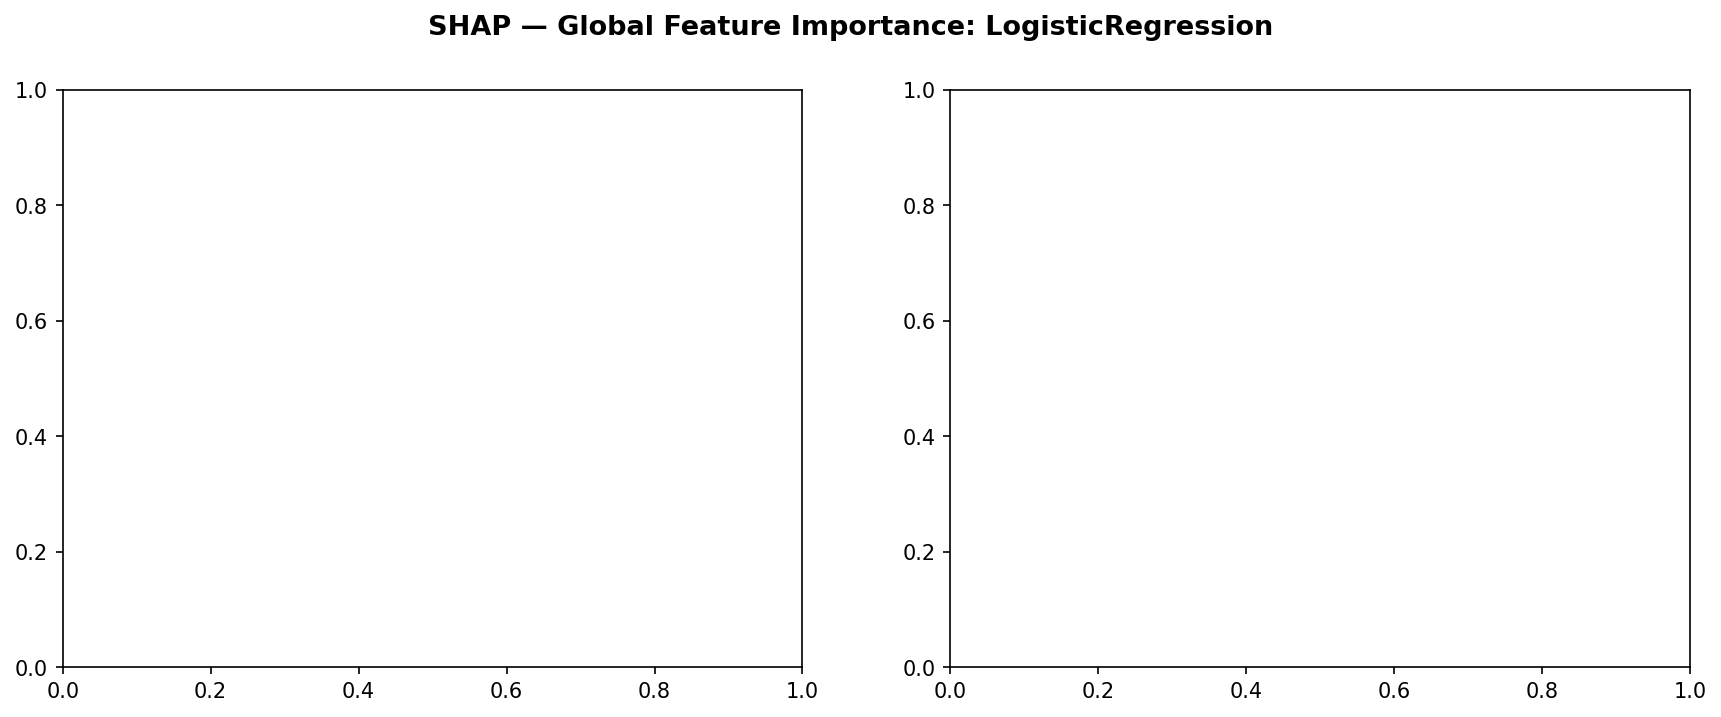

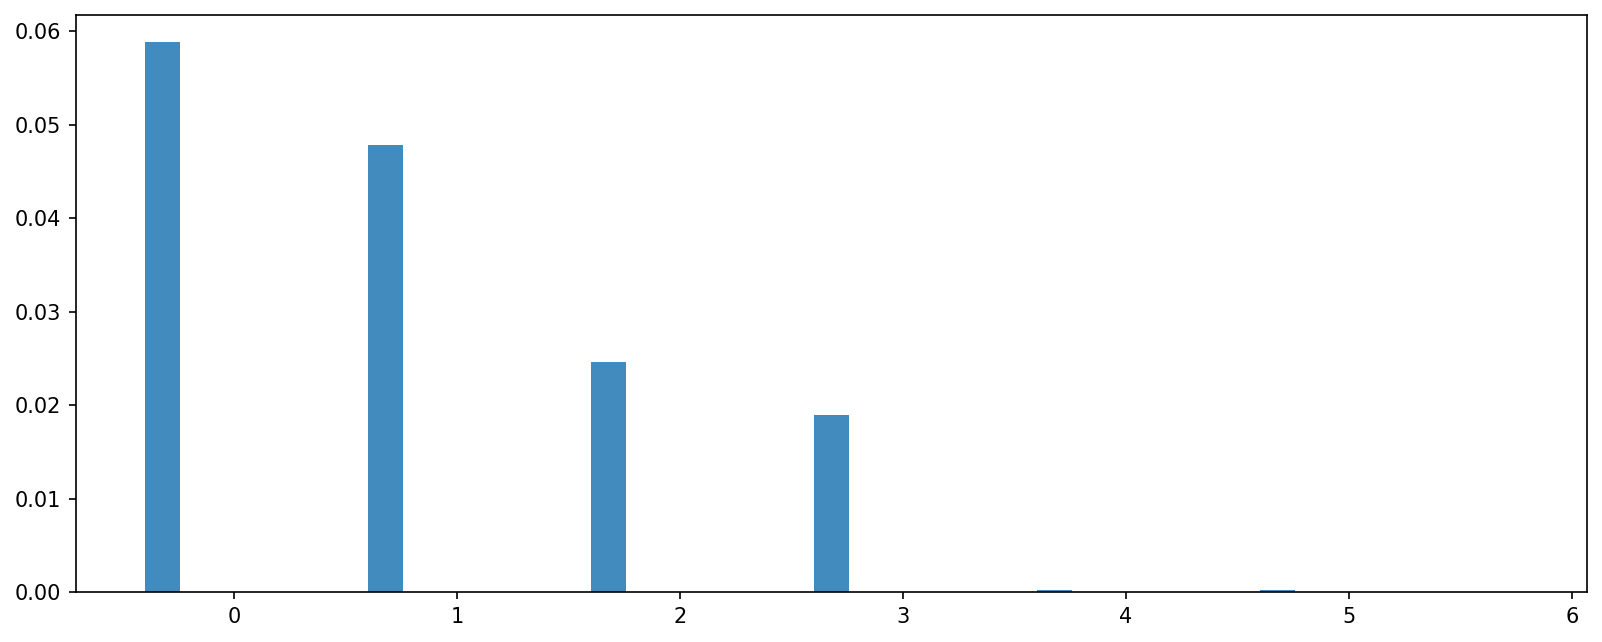

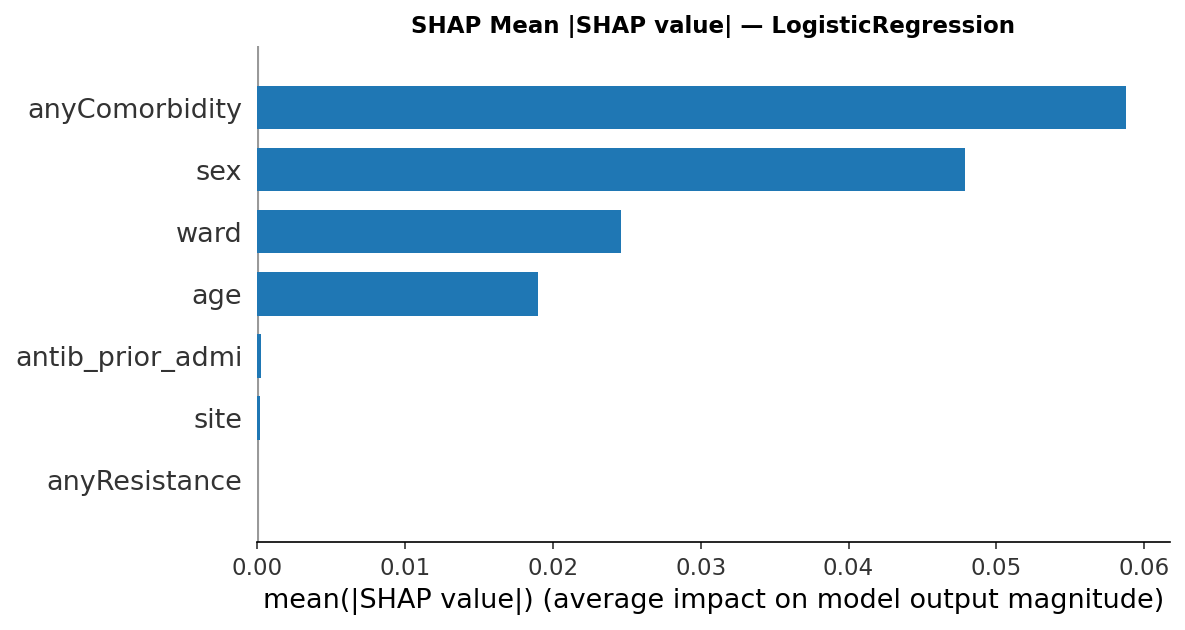

The figure layout has changed to tight


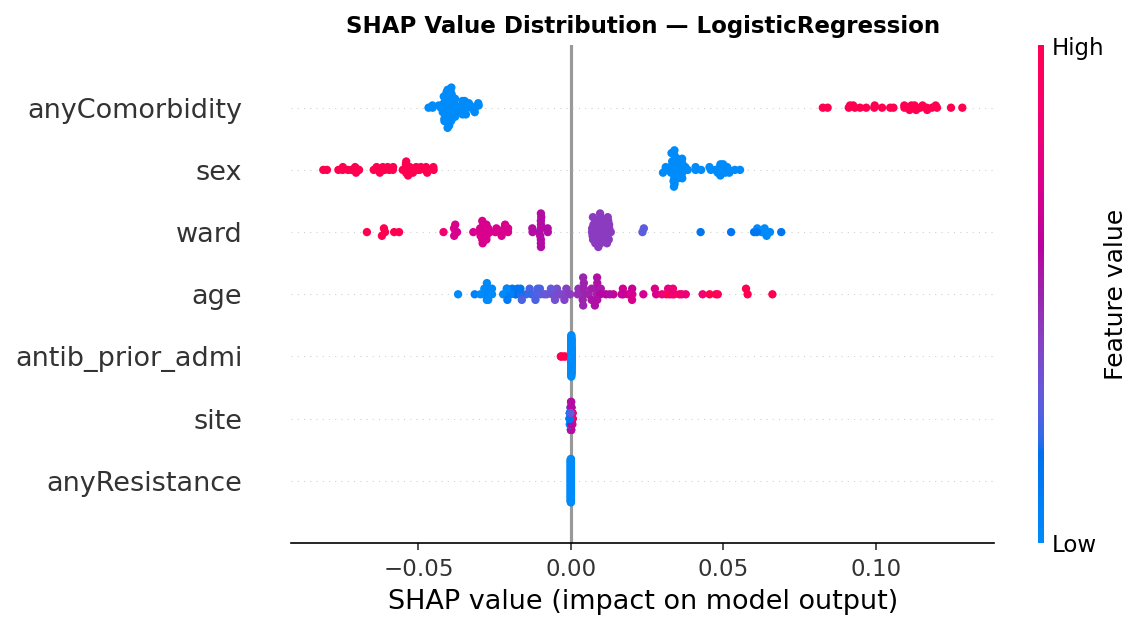

saved SHAP_bar_LogisticRegression.png, SHAP_beeswarm_LogisticRegression.png
Computing SHAP: DecisionTree ... 

PermutationExplainer explainer: 101it [00:12,  1.64it/s]                         
The figure layout has changed to tight


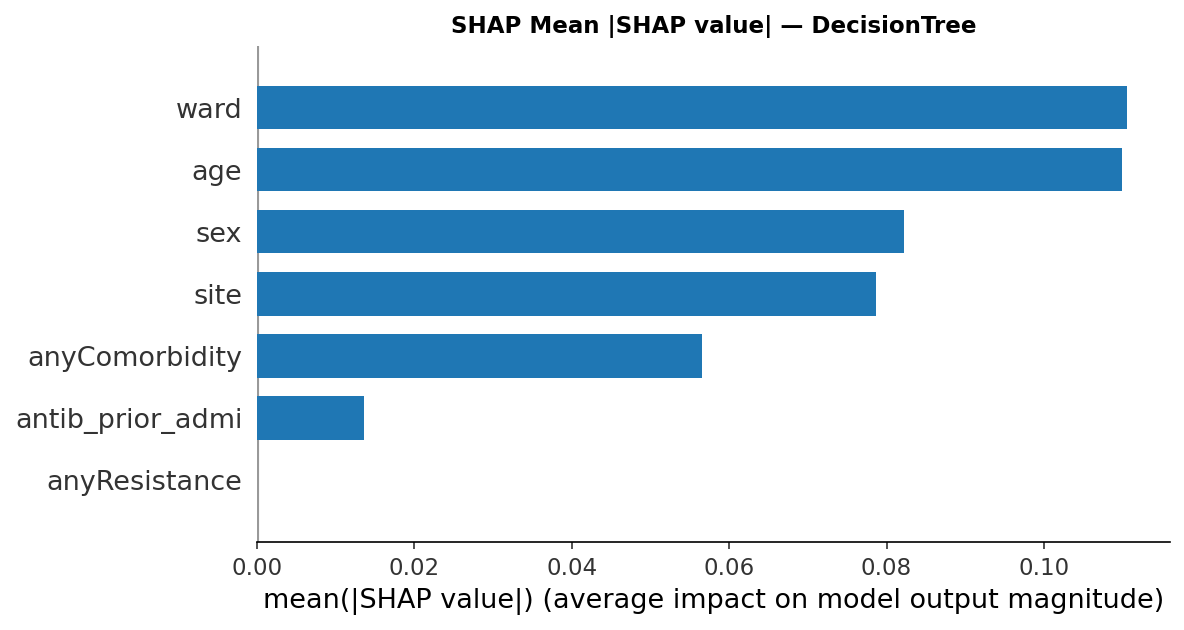

The figure layout has changed to tight


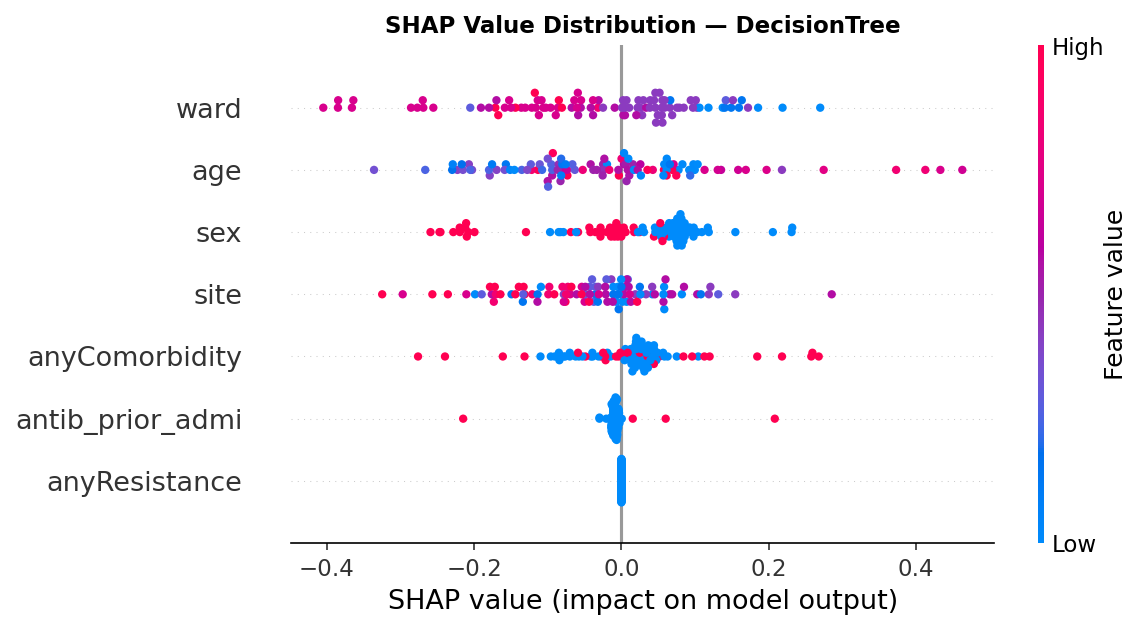

saved SHAP_bar_DecisionTree.png, SHAP_beeswarm_DecisionTree.png
Computing SHAP: RandomForest ... 

PermutationExplainer explainer: 101it [03:35,  2.24s/it]                         
The figure layout has changed to tight


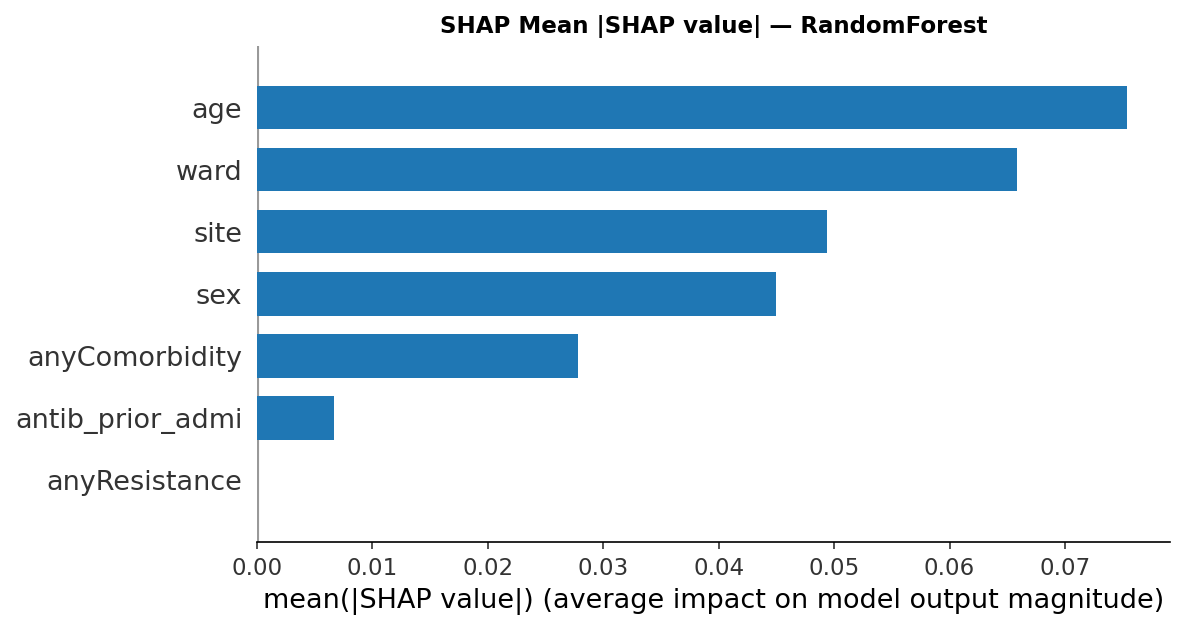

The figure layout has changed to tight


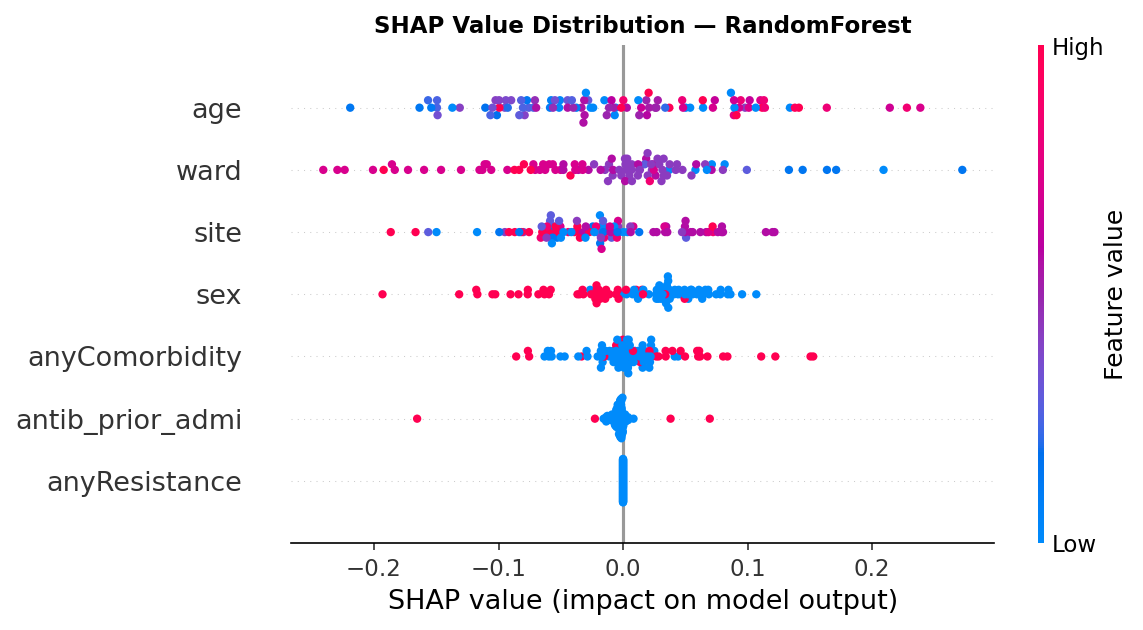

saved SHAP_bar_RandomForest.png, SHAP_beeswarm_RandomForest.png
Computing SHAP: SVM ... 

PermutationExplainer explainer: 101it [00:56,  1.42it/s]                         
The figure layout has changed to tight


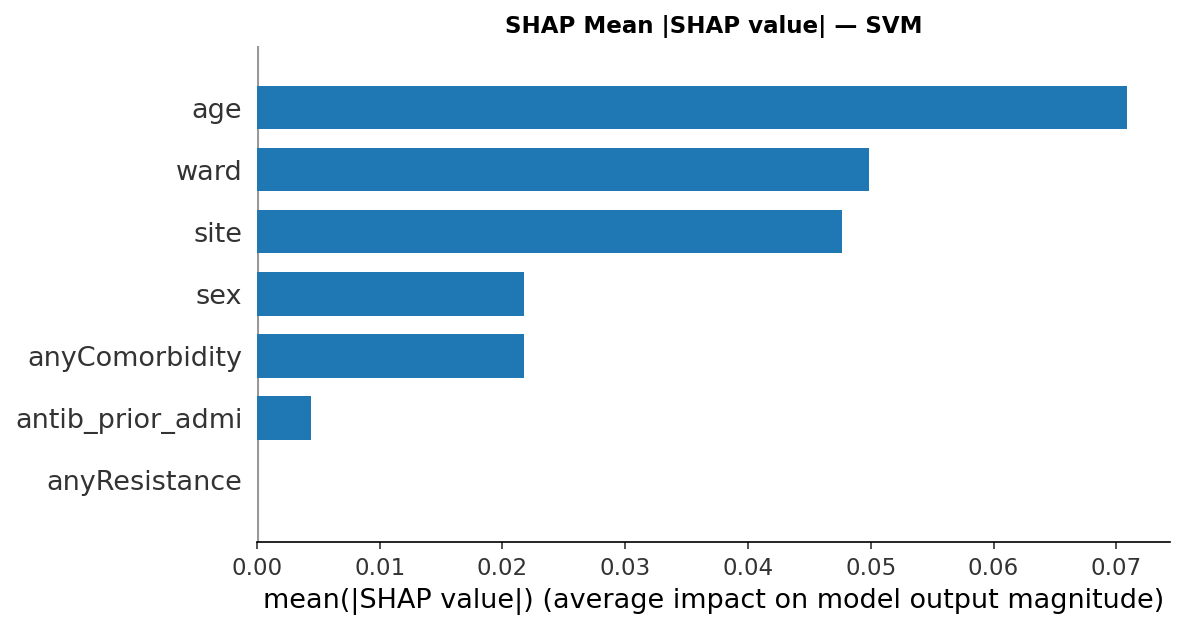

The figure layout has changed to tight


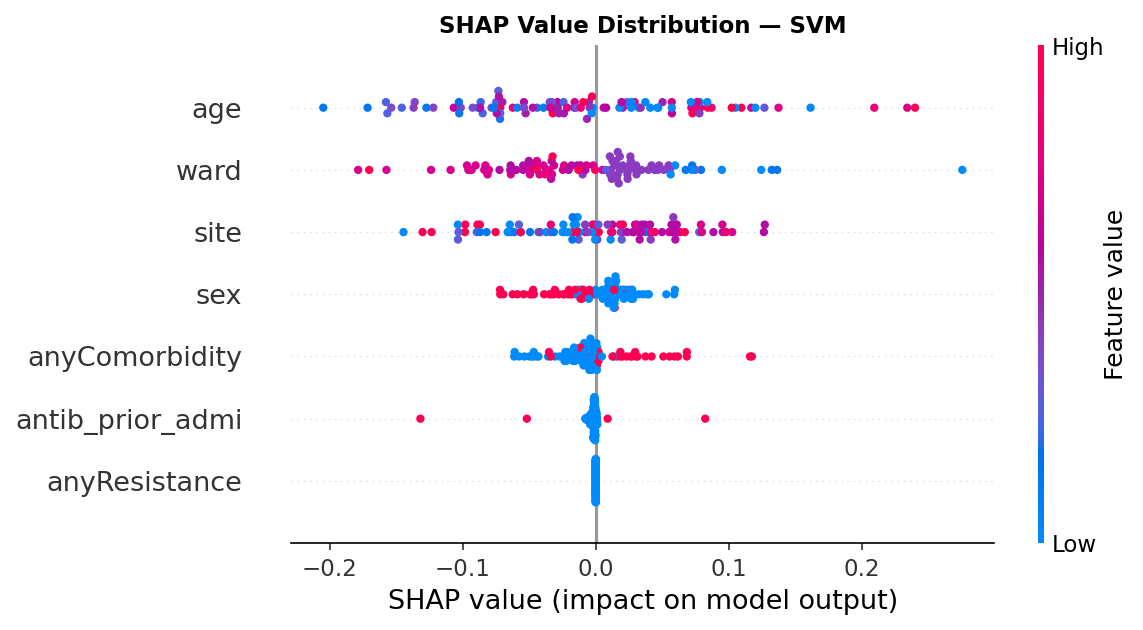

saved SHAP_bar_SVM.png, SHAP_beeswarm_SVM.png
Computing SHAP: XGBoost ... 

PermutationExplainer explainer: 101it [00:39,  1.77it/s]                         
The figure layout has changed to tight


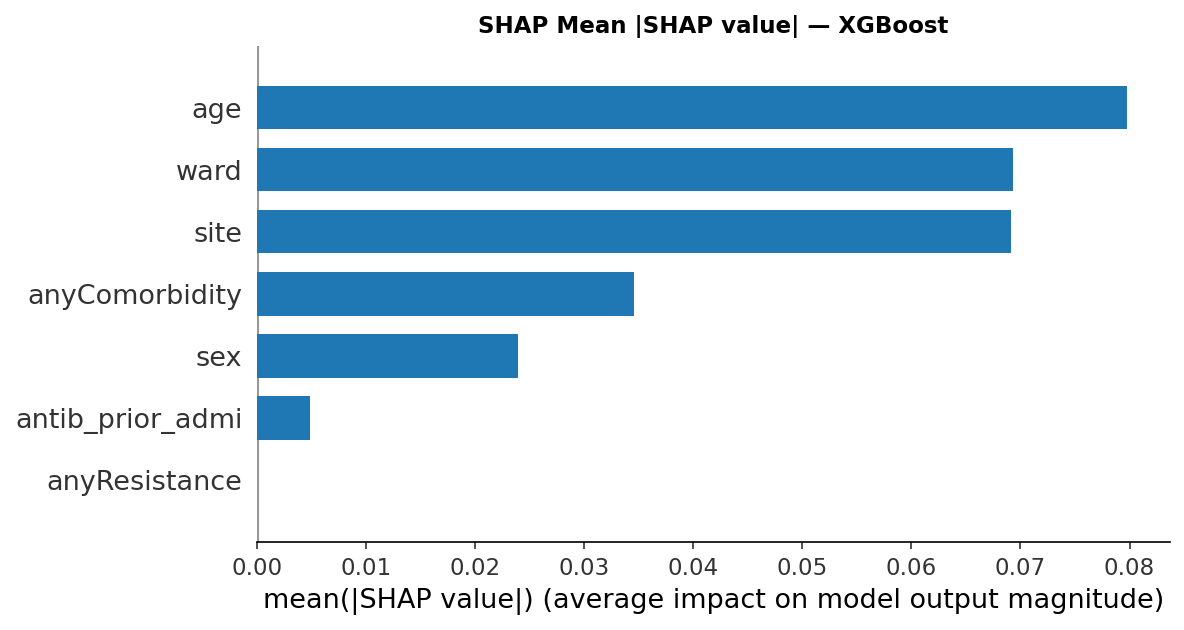

The figure layout has changed to tight


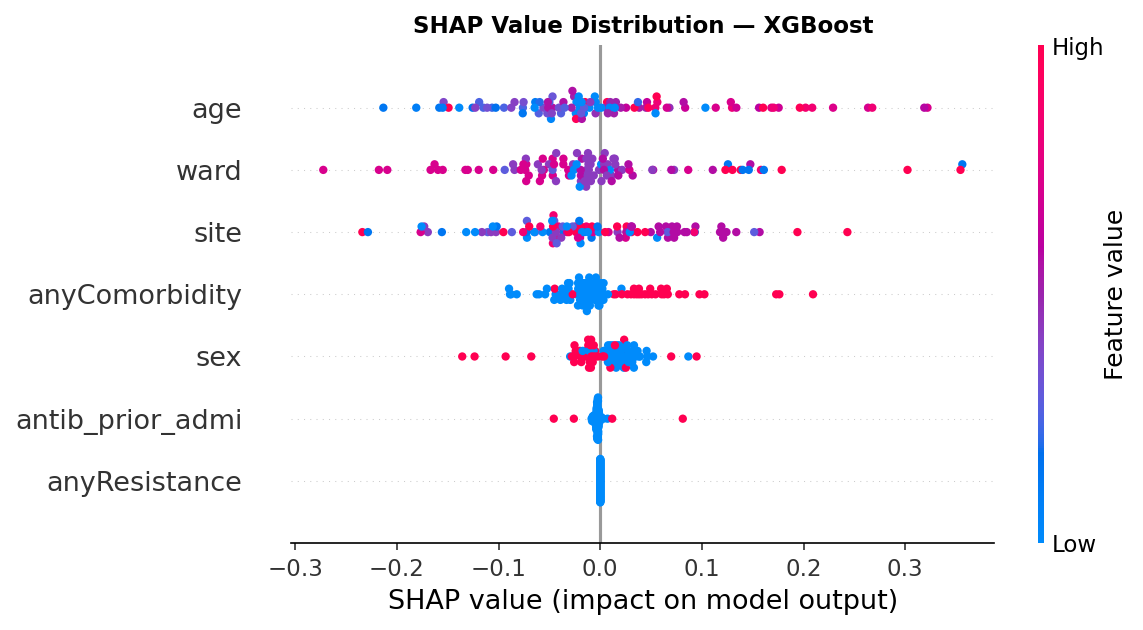

saved SHAP_bar_XGBoost.png, SHAP_beeswarm_XGBoost.png


In [81]:
# ---- SHAP config ----
N_BG      = 30    # background samples for PermutationExplainer
N_EXPLAIN = 100   # test patients to explain

X_bg      = X_test_df.sample(N_BG, random_state=42)
X_explain = X_test_df.iloc[:N_EXPLAIN].reset_index(drop=True)

shap_store = {}

for mname in MODEL_NAMES:
    model = models[mname]
    print(f"Computing SHAP: {mname} ...", end=" ", flush=True)

    predict_fn = make_predict_fn(model, predictor_cols, categorical_cols)
    explainer  = shap.PermutationExplainer(predict_fn, X_bg)
    sv         = explainer(X_explain)

    # Store a labelled Explanation for waterfall / dependence plots downstream
    sv_disp = shap.Explanation(
        values      = sv.values,
        base_values = sv.base_values,
        data        = sv.data,
        feature_names = feat_display_names,
    )
    shap_store[mname] = sv_disp
    sv_vals = sv.values          # raw numpy array for summary_plot

    # ---- bar chart (mean |SHAP|) ----
    fig_bar, ax_bar = plt.subplots(figsize=(7, 4))
    shap.summary_plot(
        sv_vals, X_explain.values,
        feature_names = feat_display_names,
        max_display   = len(predictor_cols),
        plot_type     = "bar",
        show          = False,
        color_bar     = False,
    )
    for patch in ax_bar.patches:
        patch.set_facecolor("#1f77b4")
    ax_bar.set_title(f"SHAP Mean |SHAP value| — {mname}", fontweight="bold")
    plt.tight_layout()
    bar_fname = f"SHAP_bar_{mname}.png"
    fig_bar.savefig(bar_fname, dpi=150, bbox_inches="tight")
    plt.show()

    # ---- beeswarm (dot summary) ----
    fig_bee, ax_bee = plt.subplots(figsize=(7, 4))
    shap.summary_plot(
        sv_vals, X_explain.values,
        feature_names = feat_display_names,
        max_display   = len(predictor_cols),
        show          = False,
    )
    ax_bee.set_title(f"SHAP Value Distribution — {mname}", fontweight="bold")
    plt.tight_layout()
    bee_fname = f"SHAP_beeswarm_{mname}.png"
    fig_bee.savefig(bee_fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {bar_fname}, {bee_fname}")

                      site     age     sex    ward  antib_prior_admi  \
model                                                                  
LogisticRegression  0.0002  0.0190  0.0479  0.0246            0.0003   
DecisionTree        0.0786  0.1099  0.0822  0.1105            0.0136   
RandomForest        0.0494  0.0753  0.0449  0.0658            0.0067   
SVM                 0.0477  0.0708  0.0217  0.0499            0.0044   
XGBoost             0.0691  0.0797  0.0239  0.0693            0.0049   

                    anyComorbidity  anyResistance  
model                                              
LogisticRegression          0.0588            0.0  
DecisionTree                0.0566            0.0  
RandomForest                0.0278            0.0  
SVM                         0.0217            0.0  
XGBoost                     0.0346            0.0  


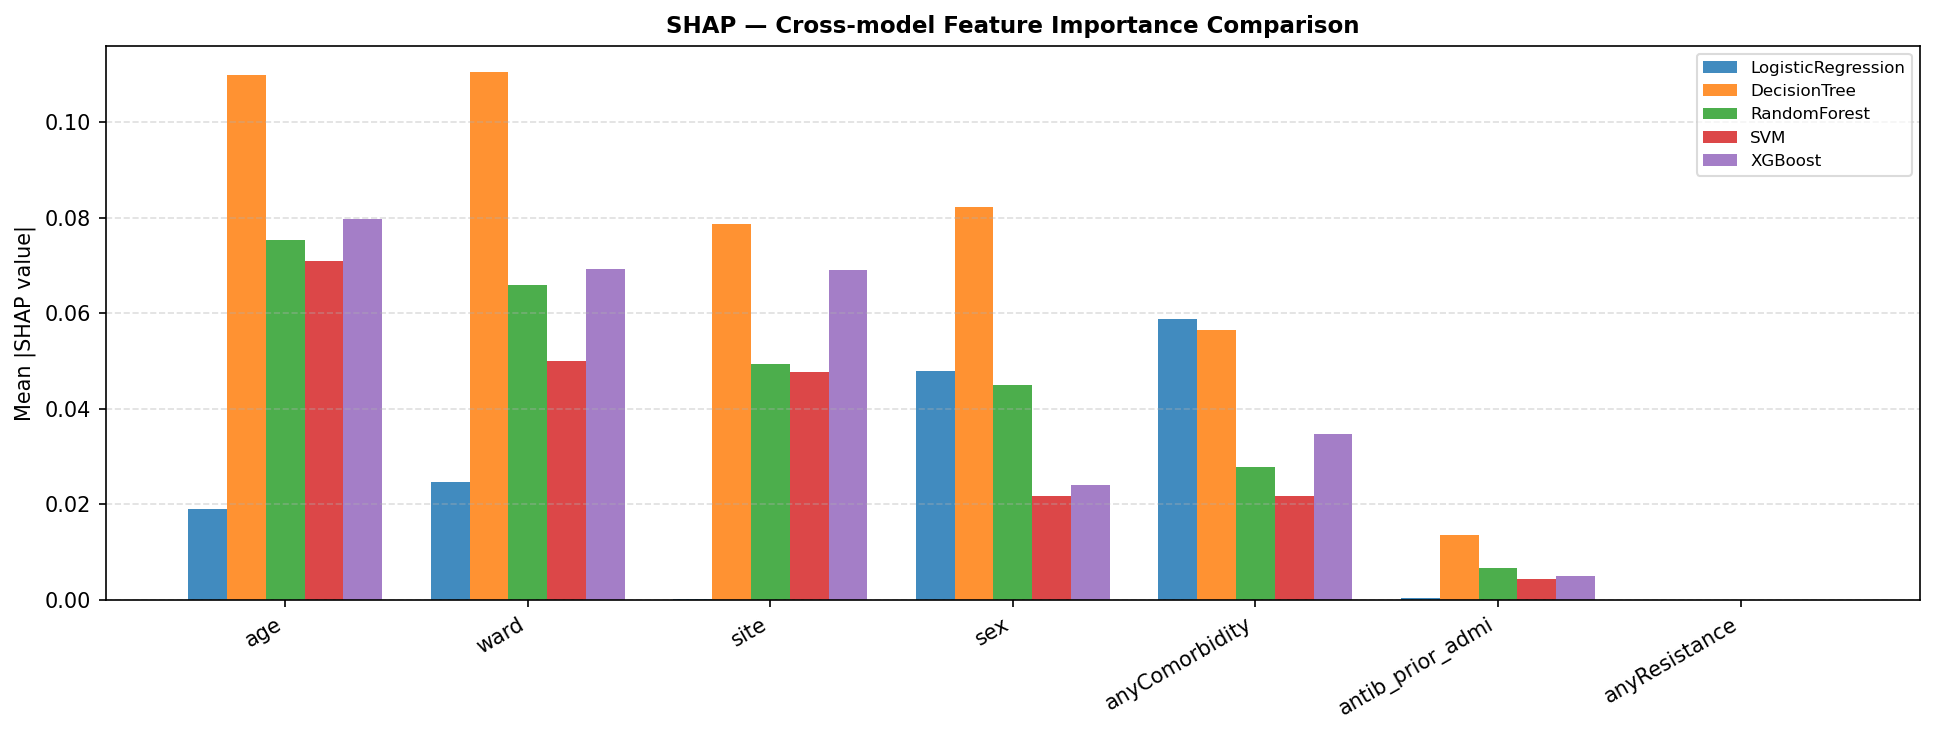

Saved SHAP_mean_abs_all_models.png


In [82]:
# ---- Build mean |SHAP| table (indexed by display names) ----
rows = []
for mname, sv in shap_store.items():
    mean_abs = np.abs(sv.values).mean(axis=0)
    row = {"model": mname}
    row.update(dict(zip(feat_display_names, mean_abs)))
    rows.append(row)

shap_importance_df = pd.DataFrame(rows).set_index("model")
shap_importance_df.to_csv("SHAP_mean_abs_importance_all_models.csv")
print(shap_importance_df.round(4))

# ---- Plot ----
feat_order = shap_importance_df.mean(axis=0).sort_values(ascending=False).index.tolist()
shap_importance_df = shap_importance_df[feat_order]

n_models = len(MODEL_NAMES)
n_feats  = len(feat_order)
bar_w    = 0.8 / n_models
x        = np.arange(n_feats)

fig, ax = plt.subplots(figsize=(13, 5))
for k, mname in enumerate(MODEL_NAMES):
    offset = (k - n_models / 2 + 0.5) * bar_w
    ax.bar(x + offset, shap_importance_df.loc[mname, feat_order],
           width=bar_w, label=mname, color=palette[k % len(palette)], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(feat_order, rotation=30, ha="right")
ax.set_ylabel("Mean |SHAP value|")
ax.set_title("SHAP — Cross-model Feature Importance Comparison", fontweight="bold")
ax.legend(loc="upper right", fontsize=8, framealpha=0.7)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
fig.savefig("SHAP_mean_abs_all_models.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved SHAP_mean_abs_all_models.png")

## SHAP — Waterfall Plot (Random Forest, Patient 0)

A waterfall plot explains one patient's prediction step-by-step: starting from
the base value (average model output), each bar shows how a feature pushes the
prediction up (red, towards Died) or down (blue, towards Survived).

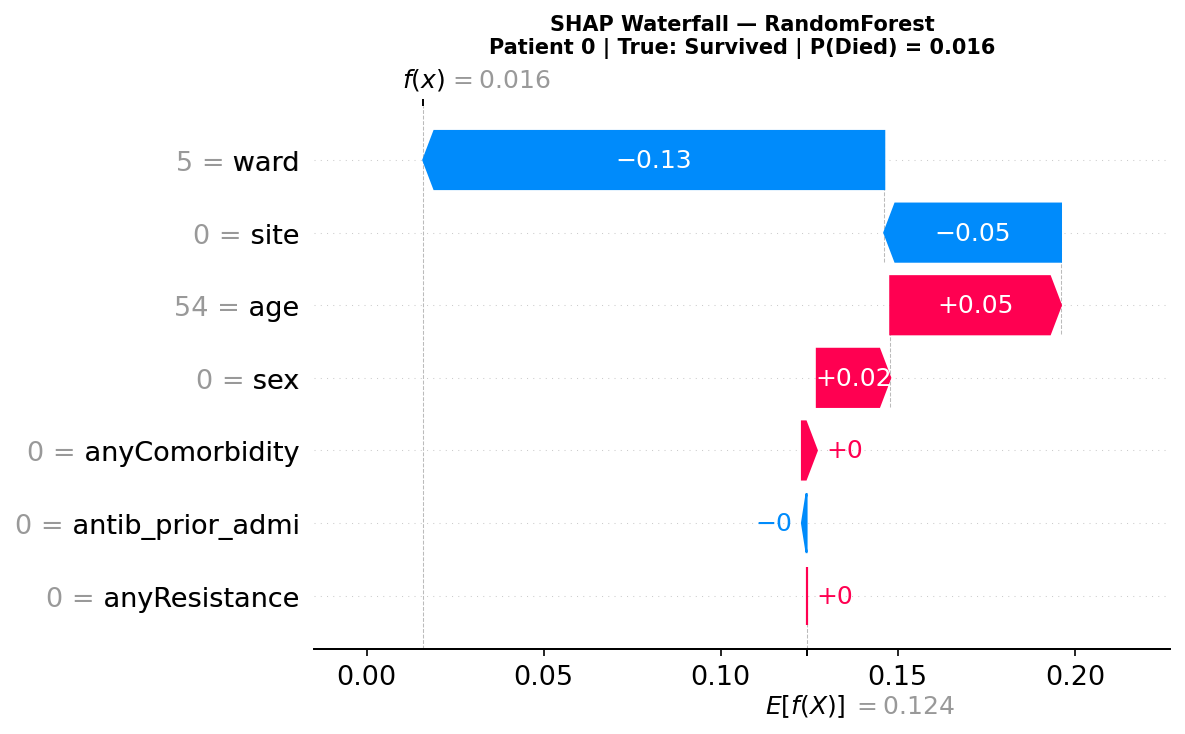

Saved SHAP_waterfall_best_model.png  |  patient 0 | true: Survived


In [83]:
PATIENT_IDX = 0

sv_best    = shap_store[BEST_MODEL]
true_label = "Died" if y_test_arr[PATIENT_IDX] == 1 else "Survived"

pred_fn_best = make_predict_proba(models[BEST_MODEL], predictor_cols, categorical_cols)
pred_prob    = pred_fn_best(X_test_df.iloc[[PATIENT_IDX]].values)[0, 1]

shap.plots.waterfall(sv_best[PATIENT_IDX], max_display=len(predictor_cols), show=False)
plt.title(
    f"SHAP Waterfall — {BEST_MODEL}\n"
    f"Patient {PATIENT_IDX} | True: {true_label} | P(Died) = {pred_prob:.3f}",
    fontsize=10, fontweight="bold",
)
plt.tight_layout()
plt.savefig("SHAP_waterfall_best_model.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved SHAP_waterfall_best_model.png  |  patient {PATIENT_IDX} | true: {true_label}")

## SHAP — Dependence Plots: Top-2 Features (Random Forest)

Each dot is one test patient. X-axis = actual feature value;
Y-axis = SHAP value (contribution to log-odds of Died).
Colour encodes the interaction feature chosen automatically by highest correlation.

Top-2 features for RandomForest: ['age', 'ward']


invalid value encountered in divide
invalid value encountered in divide
invalid value encountered in divide
invalid value encountered in divide


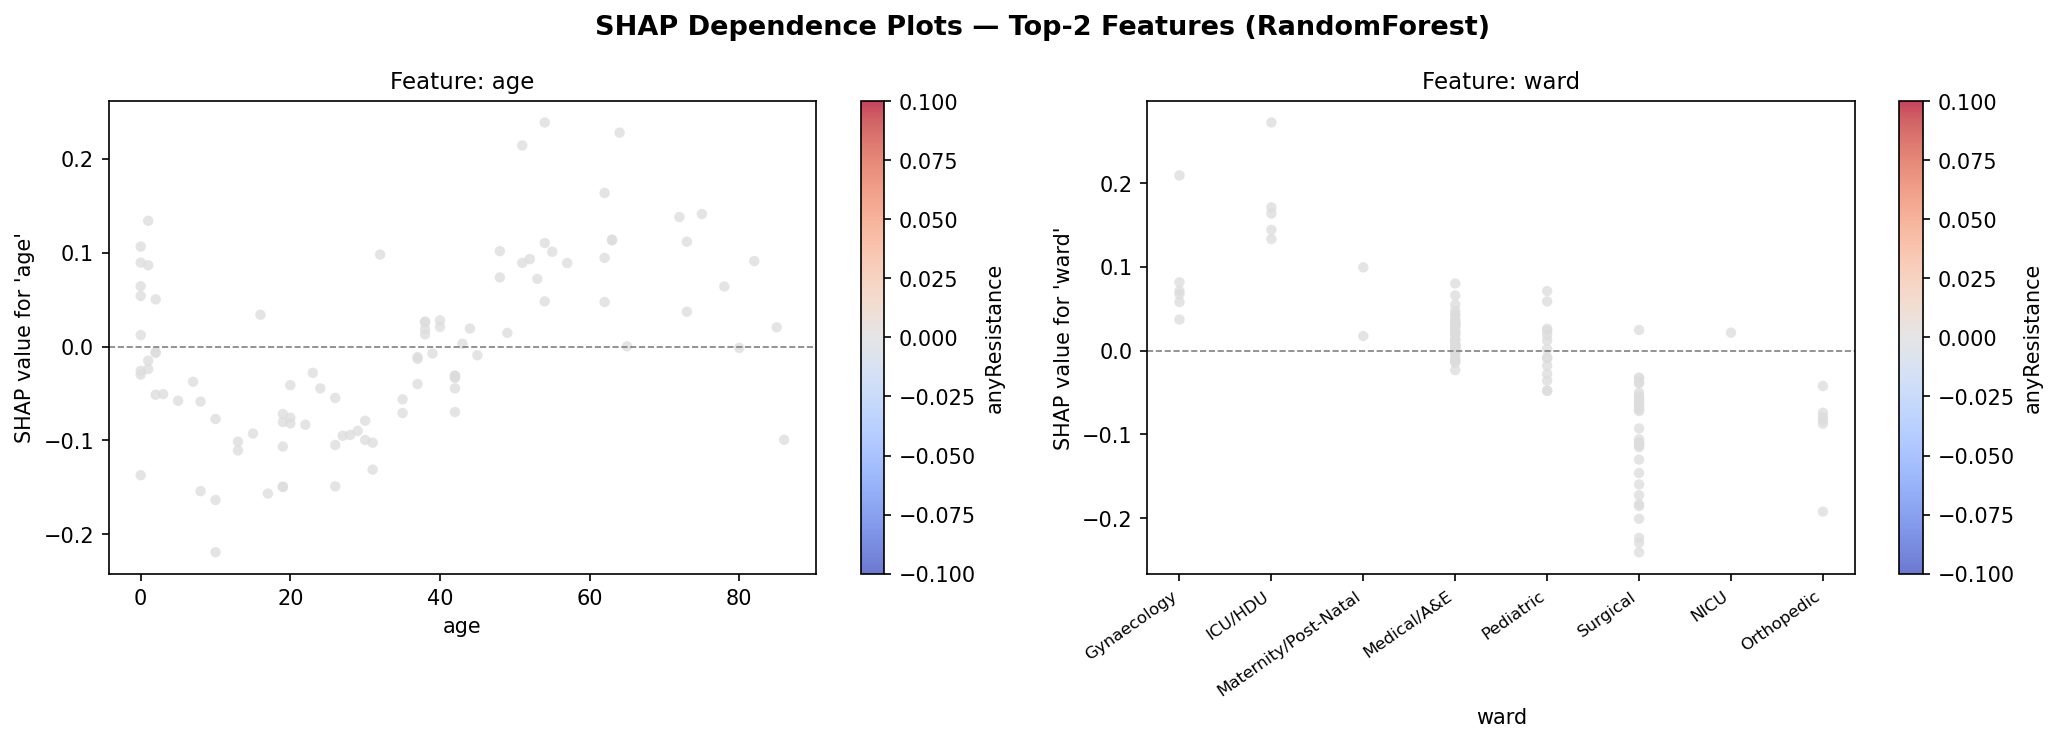

Saved SHAP_dependence_RandomForest.png  |  top features: ['age', 'ward']


In [84]:
DEP_MODEL = BEST_MODEL
sv_dep    = shap_store[DEP_MODEL]
X_dep     = X_explain.reset_index(drop=True)

ward_code_to_name = {
    0: "Gynaecology", 1: "ICU/HDU", 2: "Maternity/Post-Natal",
    3: "Medical/A&E", 4: "Pediatric", 5: "Surgical",
    6: "NICU", 7: "Orthopedic",
}

# ── Top-2 features by mean |SHAP| (in display-name space) ───────────────────
mean_abs        = np.abs(sv_dep.values).mean(axis=0)
top2_idx        = np.argsort(mean_abs)[::-1][:2]
top2_disp       = [feat_display_names[j] for j in top2_idx]
top2_orig       = [predictor_cols[j] for j in top2_idx]
print(f"Top-2 features for {DEP_MODEL}: {top2_disp}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f"SHAP Dependence Plots — Top-2 Features ({DEP_MODEL})",
             fontsize=13, fontweight="bold")

for ax, (orig_feat, disp_feat) in zip(axes, zip(top2_orig, top2_disp)):
    feat_idx  = predictor_cols.index(orig_feat)
    shap_col  = sv_dep.values[:, feat_idx]

    # auto-select interaction feature by max |correlation| with this SHAP column
    corrs    = [abs(np.corrcoef(X_dep[f].astype(float), shap_col)[0, 1])
                for f in predictor_cols if f != orig_feat]
    int_orig = [f for f in predictor_cols if f != orig_feat][int(np.argmax(corrs))]
    int_disp = name_map[int_orig]

    x_vals = X_dep[orig_feat].astype(float).values
    sc = ax.scatter(x_vals, shap_col,
                    c=X_dep[int_orig].astype(float),
                    cmap="coolwarm", alpha=0.75, edgecolors="none", s=25)
    plt.colorbar(sc, ax=ax, label=int_disp)
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
    ax.set_ylabel(f"SHAP value for '{disp_feat}'")
    ax.set_title(f"Feature: {disp_feat}")

    if orig_feat == "ward":
        present = sorted(X_dep["ward"].astype(int).unique())
        ax.set_xticks(present)
        ax.set_xticklabels([ward_code_to_name.get(c, str(c)) for c in present],
                           rotation=35, ha="right", fontsize=8)
        ax.set_xlabel("ward")
    else:
        ax.set_xlabel(disp_feat)

plt.tight_layout()
fig.savefig(f"SHAP_dependence_{DEP_MODEL}.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved SHAP_dependence_{DEP_MODEL}.png  |  top features: {top2_disp}")

## SHAP — Ward × Age Dependence (Random Forest)

Each dot is one test patient coloured by age. Shows how ward affects the
model's prediction of mortality and whether this interaction varies by age.

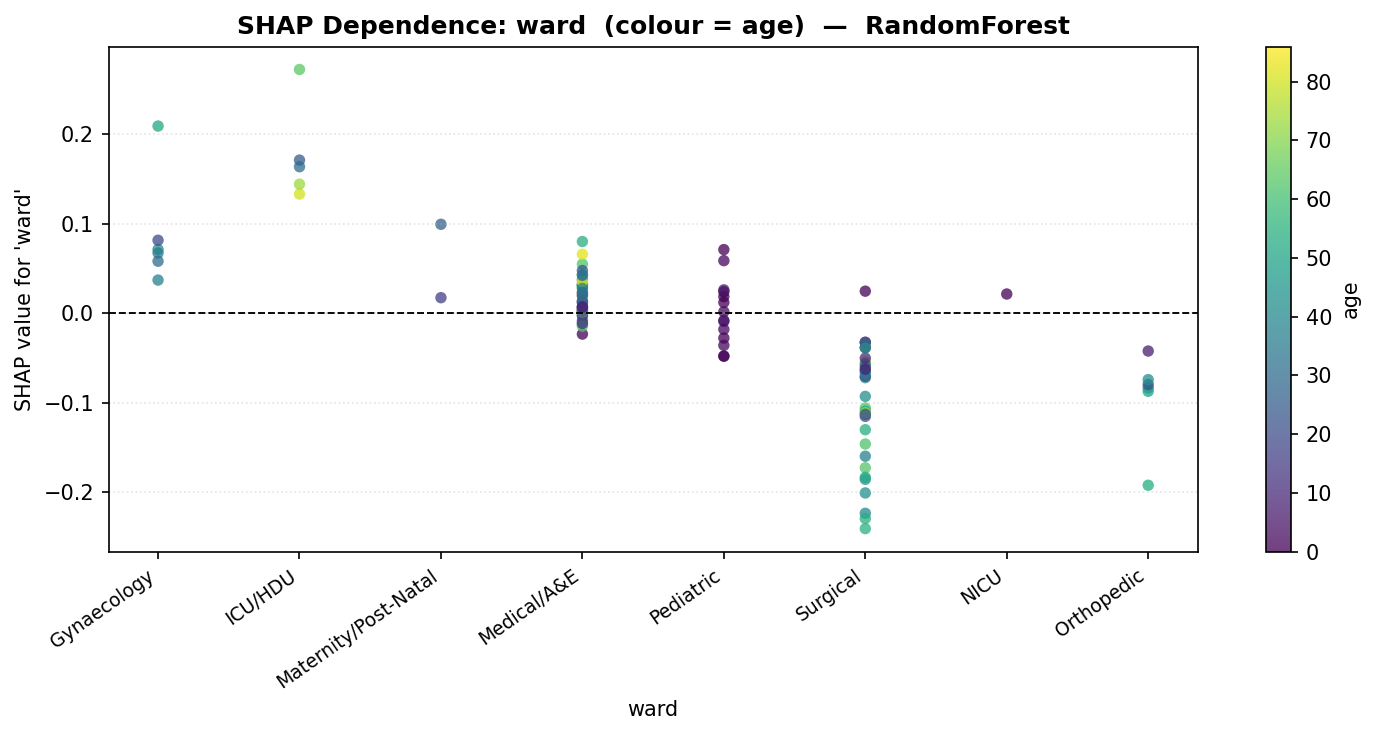

Saved SHAP_dependence_ward_age_RandomForest.png


In [85]:
DEP2_MODEL = BEST_MODEL
sv_d2      = shap_store[DEP2_MODEL]
X_d2       = X_explain.reset_index(drop=True)

ward_code_to_name = {
    0: "Gynaecology", 1: "ICU/HDU", 2: "Maternity/Post-Natal",
    3: "Medical/A&E", 4: "Pediatric", 5: "Surgical",
    6: "NICU", 7: "Orthopedic",
}

age_vals  = X_d2["age"].astype(float).values
ward_vals = X_d2["ward"].astype(float).values
shap_ward = sv_d2.values[:, predictor_cols.index("ward")]

present_codes = sorted(X_d2["ward"].astype(int).unique())
tick_labels   = [ward_code_to_name.get(c, str(c)) for c in present_codes]

fig, ax = plt.subplots(figsize=(10, 5))
sc = ax.scatter(ward_vals, shap_ward,
                c=age_vals, cmap="viridis",
                alpha=0.75, s=30, edgecolors="none")
plt.colorbar(sc, ax=ax, label="age")
ax.axhline(0, color="black", linewidth=0.9, linestyle="--")
ax.set_xticks(present_codes)
ax.set_xticklabels(tick_labels, rotation=35, ha="right", fontsize=9)
ax.set_xlabel("ward", fontsize=10)
ax.set_ylabel("SHAP value for 'ward'", fontsize=10)
ax.set_title(f"SHAP Dependence: ward  (colour = age)  —  {DEP2_MODEL}",
             fontsize=12, fontweight="bold")
ax.grid(axis="y", linestyle=":", alpha=0.35)
plt.tight_layout()
fname = f"SHAP_dependence_ward_age_{DEP2_MODEL}.png"
fig.savefig(fname, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {fname}")

## SHAP — Violin Plot (Random Forest)

The violin plot combines SHAP values with a density estimate. Width at any
SHAP value = how many patients had that SHAP value for the feature.
Colour = feature value (red = high, blue = low).

The figure layout has changed to tight


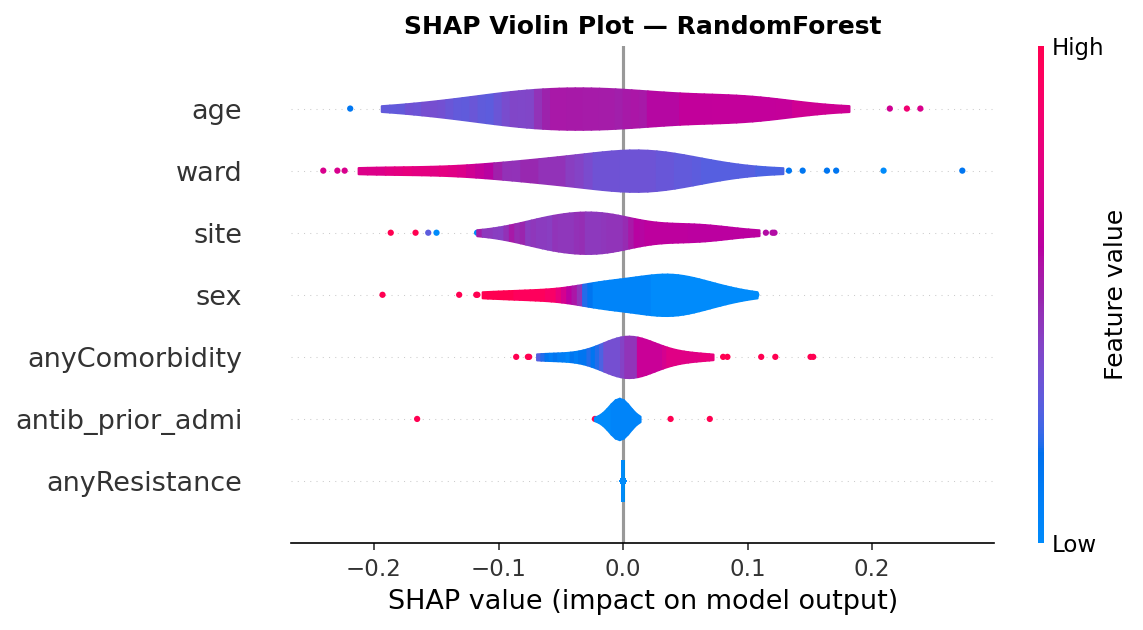

Saved SHAP_violin_RandomForest.png


In [86]:
VIO_MODEL = BEST_MODEL
sv_vio    = shap_store[VIO_MODEL]

shap.summary_plot(
    sv_vio.values,
    X_explain.values,
    plot_type     = "violin",
    feature_names = feat_display_names,
    max_display   = len(predictor_cols),
    show          = False,
    color_bar     = True,
)
plt.title(f"SHAP Violin Plot — {VIO_MODEL}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(f"SHAP_violin_{VIO_MODEL}.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved SHAP_violin_{VIO_MODEL}.png")

## LIME — Local Explanations Across All Models

LIME fits a simple linear model in the neighbourhood of a single patient and
returns per-feature weights that explain *that specific prediction*.
A positive weight pushes towards Died; negative towards Survived.

In [87]:
from sklearn.preprocessing import OrdinalEncoder

# ---- Encode categoricals to integer codes for LIME (needs float matrix) ----
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
enc.fit(X_train_df[categorical_cols])

def encode_X(df):
    num_part = df[numeric_cols].values.astype(float)
    cat_part = enc.transform(df[categorical_cols])
    return np.hstack([num_part, cat_part])

# internal column order: numeric first, then categorical
all_feat_names   = numeric_cols + categorical_cols
all_disp_names   = [name_map[f] for f in all_feat_names]
cat_feat_idxs    = list(range(len(numeric_cols), len(all_feat_names)))

X_train_lime = encode_X(X_train_df)
X_test_lime  = encode_X(X_test_df)

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data        = X_train_lime,
    feature_names        = all_disp_names,   # display labels in figures
    class_names          = ["Survived", "Died"],
    categorical_features = cat_feat_idxs,
    mode                 = "classification",
    random_state         = 42,
)

def lime_predict_fn(model):
    """Returns fn(float array) -> (n,2) probability array for LIME."""
    def fn(X_np):
        num_part = X_np[:, :len(numeric_cols)]
        cat_part = X_np[:, len(numeric_cols):]
        df = pd.DataFrame(num_part, columns=numeric_cols)
        for j, col in enumerate(categorical_cols):
            codes = cat_part[:, j].astype(int).clip(0)
            cats  = enc.categories_[j]
            df[col] = [cats[c] if c < len(cats) else cats[0] for c in codes]
        X_orig = df[predictor_cols].copy()
        for col in categorical_cols:
            X_orig[col] = X_orig[col].astype("category")
        if hasattr(model, "predict_proba"):
            return model.predict_proba(X_orig)
        scores = model.decision_function(X_orig)
        p1 = 1.0 / (1.0 + np.exp(-scores))
        return np.column_stack([1 - p1, p1])
    return fn

print("LIME explainer ready.")
print(f"Display feature order: {all_disp_names}")

LIME explainer ready.
Display feature order: ['age', 'site', 'sex', 'ward', 'antib_prior_admi', 'anyComorbidity', 'anyResistance']


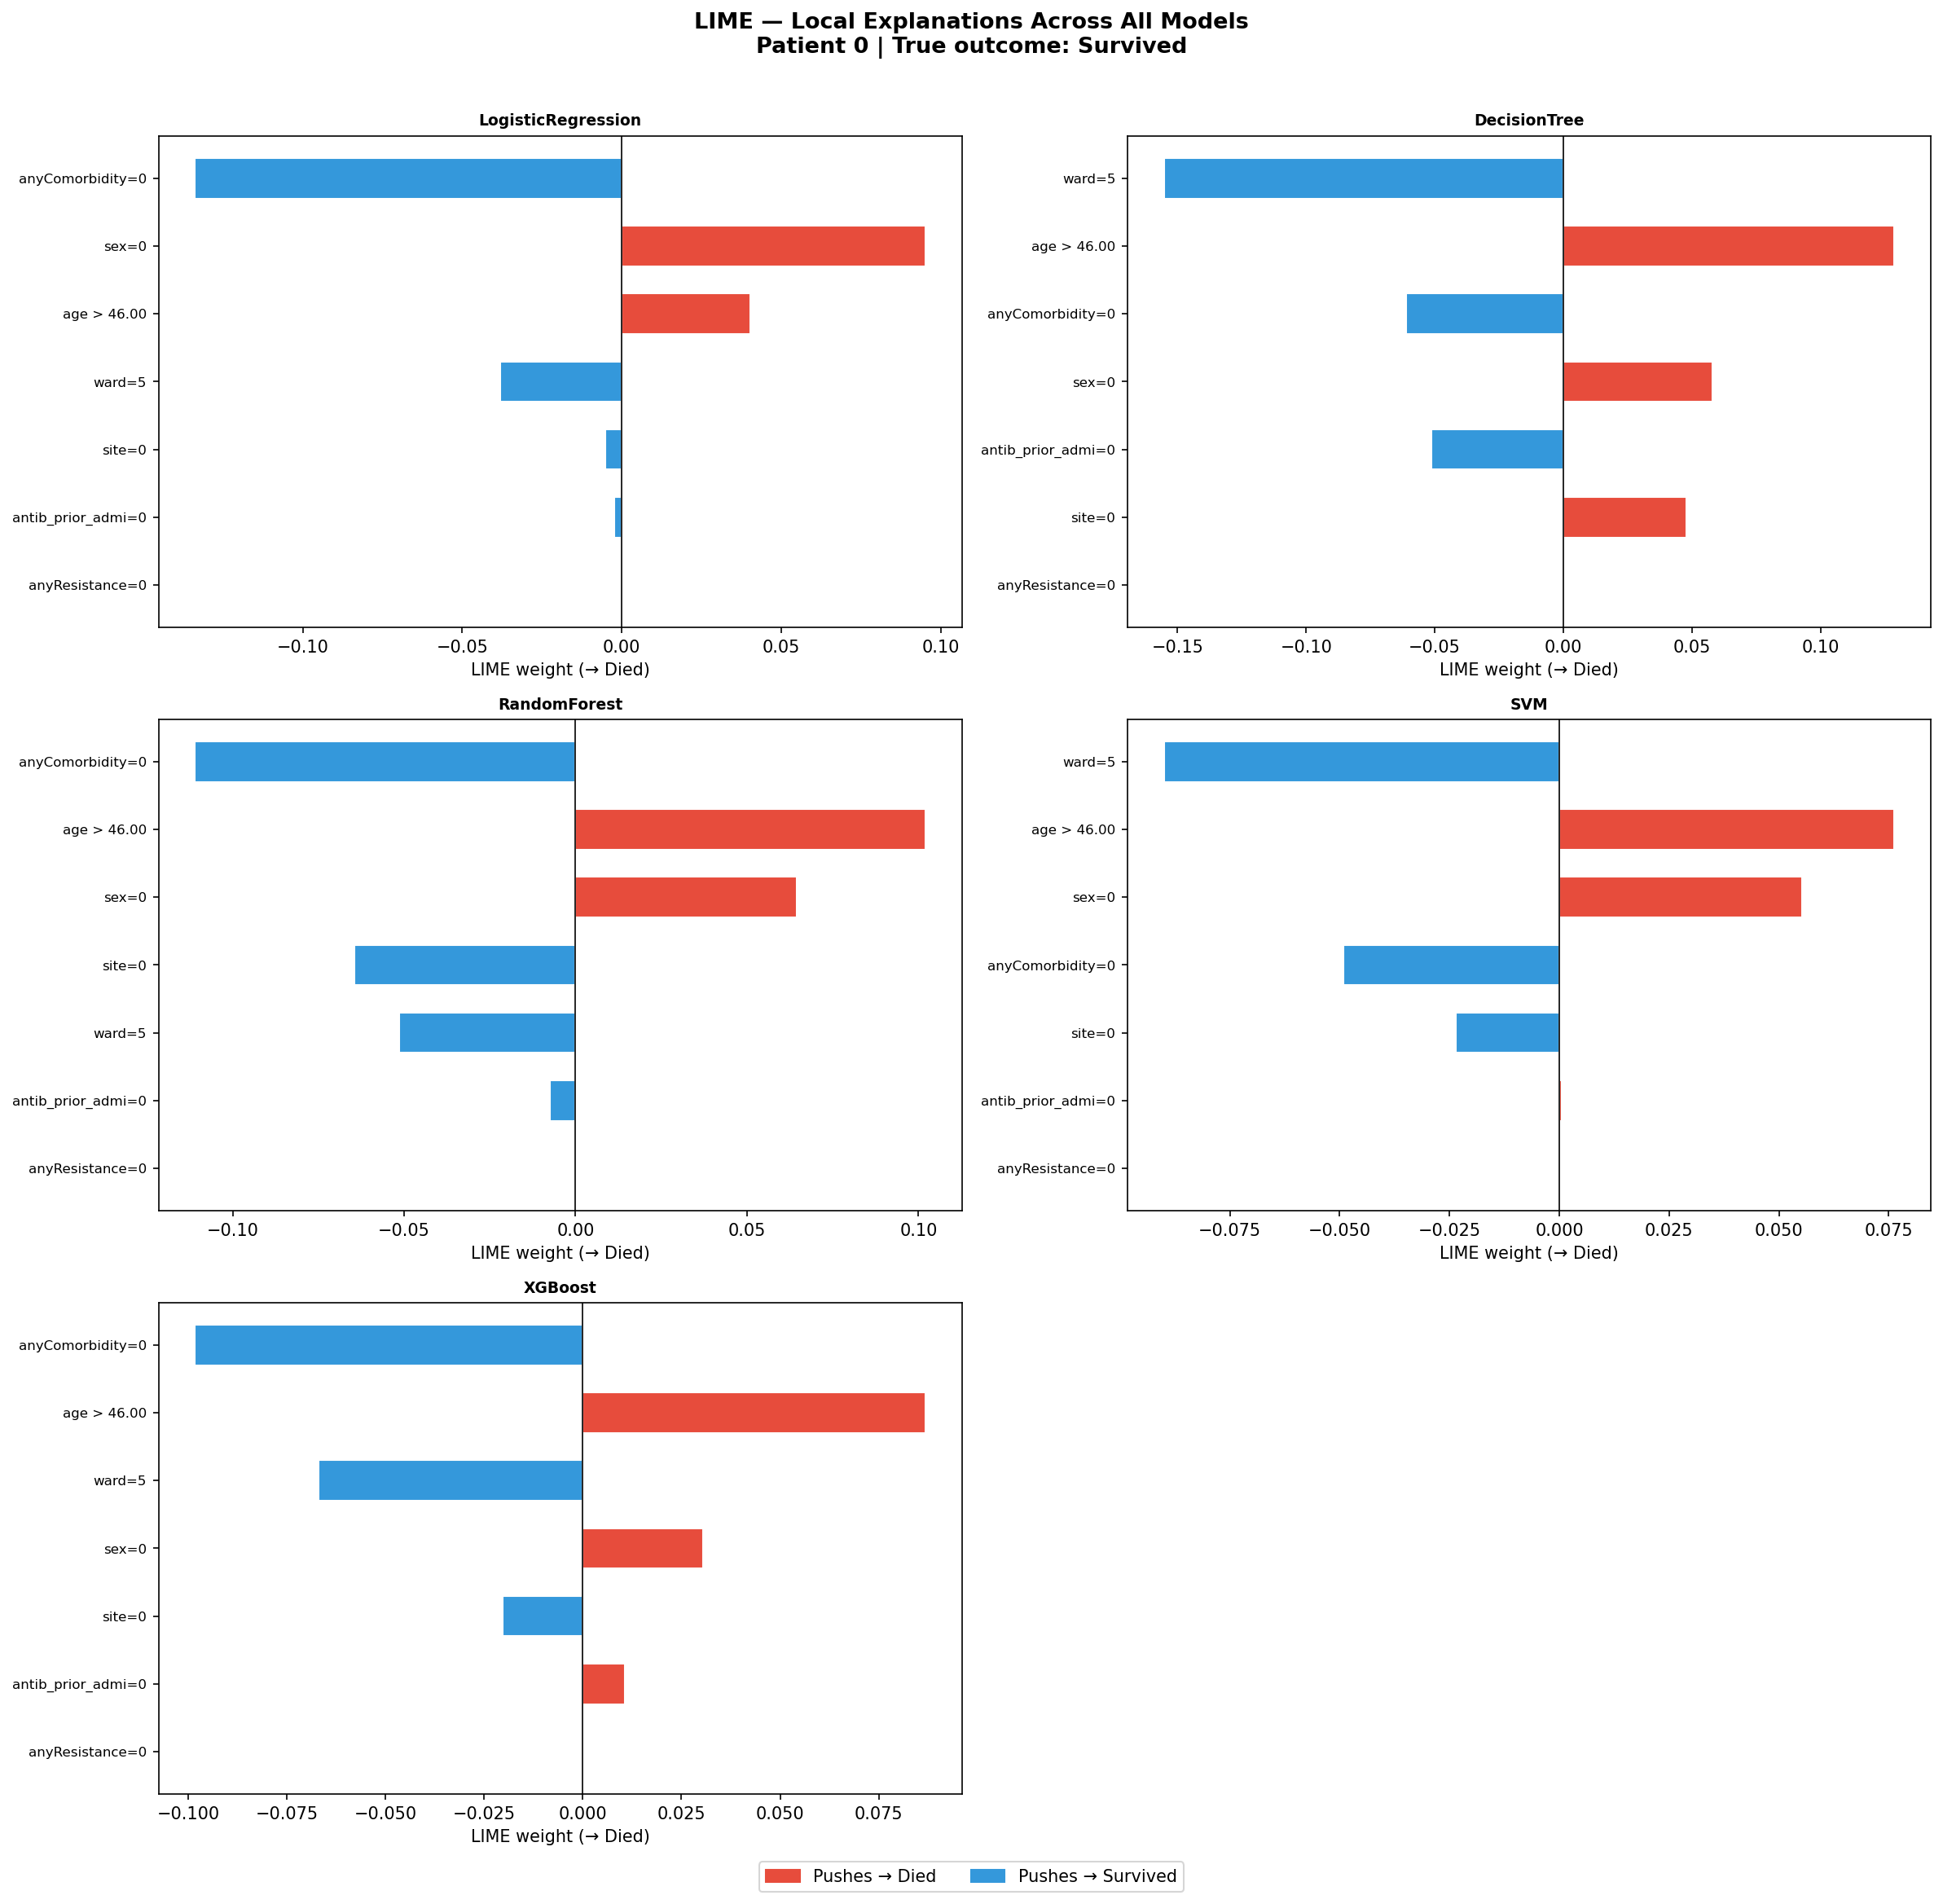

Saved LIME_local_all_models.png


In [88]:
LIME_PATIENT = 0
instance     = X_test_lime[LIME_PATIENT]
true_label   = "Died" if y_test_arr[LIME_PATIENT] == 1 else "Survived"

n_cols = 2
n_rows = (len(MODEL_NAMES) + 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

for k, mname in enumerate(MODEL_NAMES):
    exp = lime_explainer.explain_instance(
        instance,
        lime_predict_fn(models[mname]),
        num_features = len(all_feat_names),
        num_samples  = 1000,
        labels       = (1,),
    )
    feat_vals = exp.as_list(label=1)
    ax      = axes[k]
    labels_ = [fv[0] for fv in feat_vals]
    weights = [fv[1] for fv in feat_vals]
    colours = ["#e74c3c" if w > 0 else "#3498db" for w in weights]

    y_pos = np.arange(len(labels_))
    ax.barh(y_pos, weights, color=colours, edgecolor="white", height=0.6)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels_, fontsize=8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("LIME weight (→ Died)")
    ax.set_title(mname, fontsize=9, fontweight="bold")
    ax.invert_yaxis()

for j in range(len(MODEL_NAMES), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    f"LIME — Local Explanations Across All Models\nPatient {LIME_PATIENT} | True outcome: {true_label}",
    fontsize=13, fontweight="bold", y=1.01,
)
red_patch  = mpatches.Patch(color="#e74c3c", label="Pushes → Died")
blue_patch = mpatches.Patch(color="#3498db", label="Pushes → Survived")
fig.legend(handles=[red_patch, blue_patch], loc="lower center",
           ncol=2, bbox_to_anchor=(0.5, -0.02), fontsize=10)

plt.tight_layout()
fig.savefig("LIME_local_all_models.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved LIME_local_all_models.png")

## LIME — Four Representative Instances (Random Forest)

Four clinically meaningful cases:
- **True Positive** (predicted Died | actually Died)
- **True Negative** (predicted Survived | actually Survived)
- **False Positive** (predicted Died | actually Survived)
- **False Negative** (predicted Survived | actually Died)

Case indices:
  True Positive                                      -> test index 57
  True Negative                                      -> test index 0
  False Positive                                     -> test index 62
  False Negative                                     -> test index 12


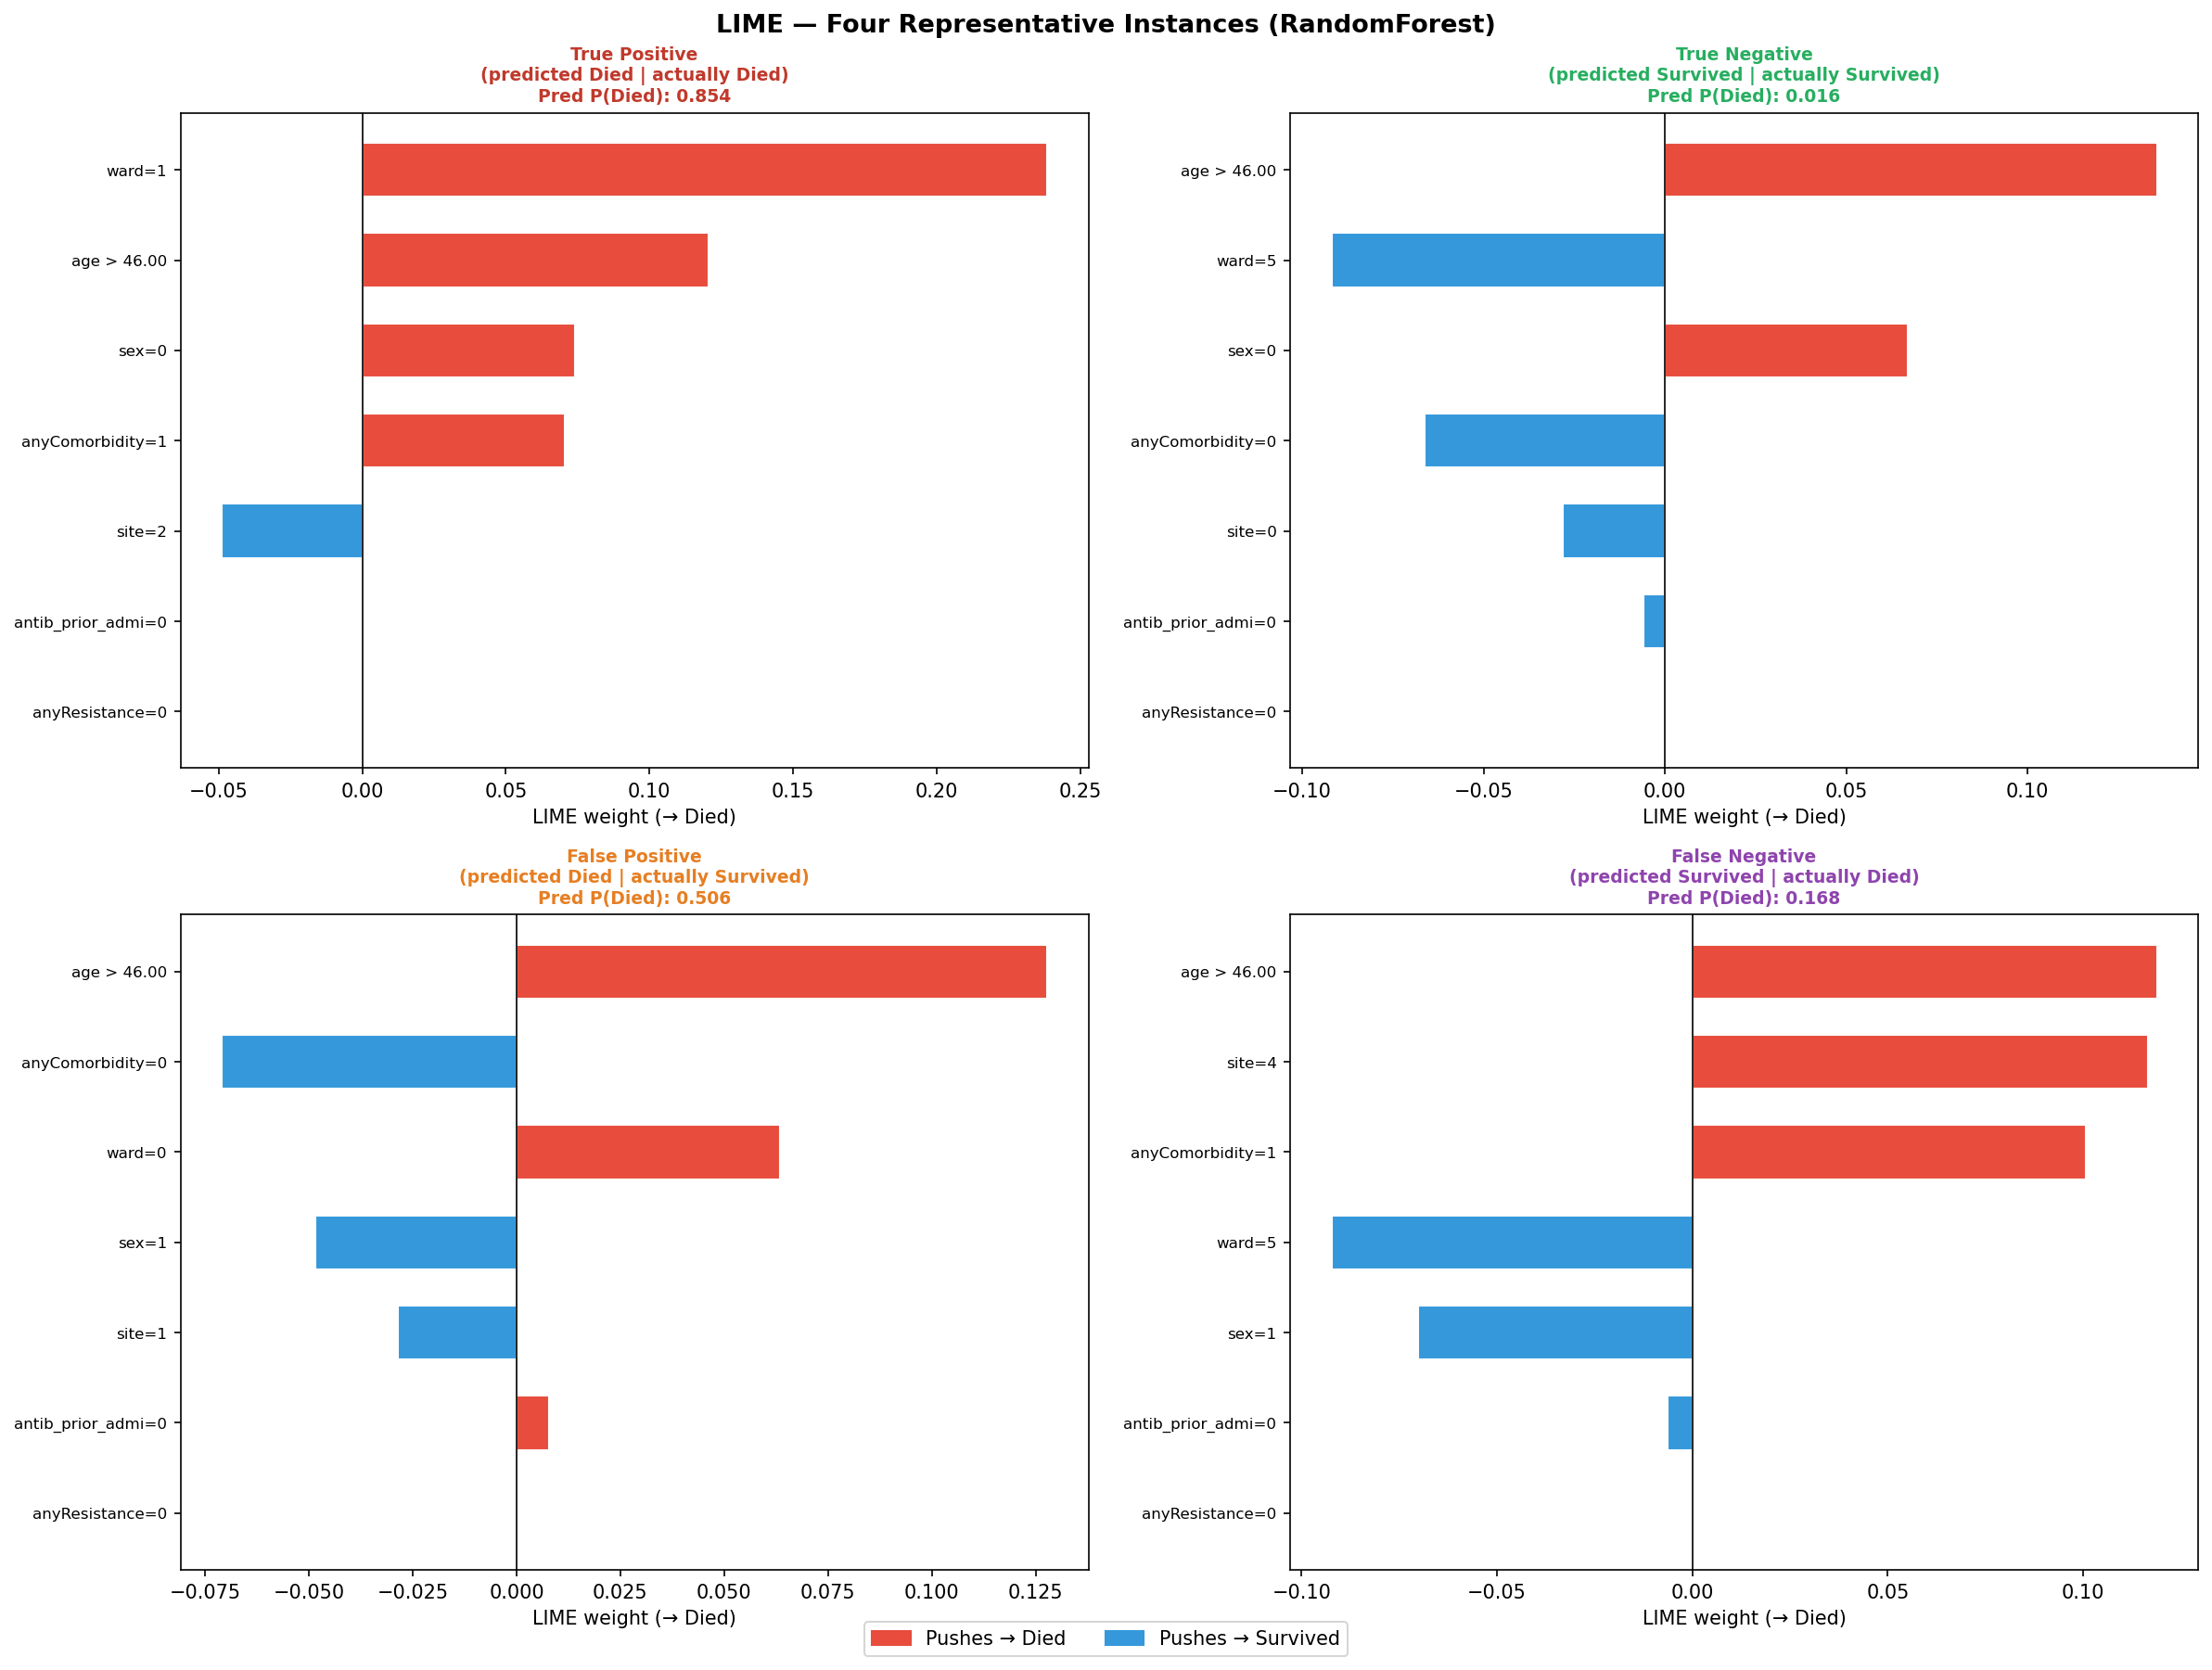

Saved LIME_four_cases_RandomForest.png


In [89]:
FOUR_MODEL = BEST_MODEL
pred_fn_four = lime_predict_fn(models[FOUR_MODEL])

test_probs_four = make_predict_proba(
    models[FOUR_MODEL], predictor_cols, categorical_cols)(X_test_df.values)[:, 1]
test_preds_four = (test_probs_four >= 0.5).astype(int)

def find_case(y_true, y_pred, true_val, pred_val):
    for idx in range(len(y_true)):
        if y_true[idx] == true_val and y_pred[idx] == pred_val:
            return idx
    return None

case_indices = {
    "True Positive\n(predicted Died | actually Died)":
        find_case(y_test_arr, test_preds_four, 1, 1),
    "True Negative\n(predicted Survived | actually Survived)":
        find_case(y_test_arr, test_preds_four, 0, 0),
    "False Positive\n(predicted Died | actually Survived)":
        find_case(y_test_arr, test_preds_four, 0, 1),
    "False Negative\n(predicted Survived | actually Died)":
        find_case(y_test_arr, test_preds_four, 1, 0),
}
print("Case indices:")
for label, idx in case_indices.items():
    print(f"  {label.split(chr(10))[0]:50s} -> test index {idx}")

CASE_COLORS = {
    "True Positive":  "#c0392b",
    "True Negative":  "#27ae60",
    "False Positive": "#e67e22",
    "False Negative": "#8e44ad",
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for k, (case_label, idx) in enumerate(case_indices.items()):
    ax = axes[k]
    if idx is None:
        ax.set_title(f"{case_label}\n(no instance found)", fontsize=9)
        ax.axis("off")
        continue

    exp = lime_explainer.explain_instance(
        X_test_lime[idx], pred_fn_four,
        num_features=len(all_feat_names), num_samples=1000, labels=(1,),
    )
    feat_vals = exp.as_list(label=1)
    labels_   = [fv[0] for fv in feat_vals]
    weights_  = [fv[1] for fv in feat_vals]
    colours_  = ["#e74c3c" if w > 0 else "#3498db" for w in weights_]

    y_pos = np.arange(len(labels_))
    ax.barh(y_pos, weights_, color=colours_, edgecolor="white", height=0.6)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels_, fontsize=8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("LIME weight (→ Died)")
    short = case_label.split("\n")[0]
    ax.set_title(
        f"{case_label}\nPred P(Died): {test_probs_four[idx]:.3f}",
        fontsize=9, fontweight="bold", color=CASE_COLORS.get(short, "black"),
    )
    ax.invert_yaxis()

    # save individual PNG
    fig_i, ax_i = plt.subplots(figsize=(8, 5))
    ax_i.barh(y_pos, weights_, color=colours_, edgecolor="white", height=0.6)
    ax_i.set_yticks(y_pos); ax_i.set_yticklabels(labels_, fontsize=9)
    ax_i.axvline(0, color="black", linewidth=0.8)
    ax_i.set_xlabel("LIME weight (→ Died)")
    ax_i.set_title(f"LIME — {FOUR_MODEL}\n{case_label.replace(chr(10), ' ')} | P(Died): {test_probs_four[idx]:.3f}",
                   fontsize=10, fontweight="bold")
    ax_i.invert_yaxis()
    plt.tight_layout()
    safe = short.replace(" ", "_")
    fig_i.savefig(f"LIME_{FOUR_MODEL}_{safe}.png", dpi=150, bbox_inches="tight")
    plt.close(fig_i)

fig.suptitle(f"LIME — Four Representative Instances ({FOUR_MODEL})",
             fontsize=13, fontweight="bold")
red_p  = mpatches.Patch(color="#e74c3c", label="Pushes → Died")
blue_p = mpatches.Patch(color="#3498db", label="Pushes → Survived")
fig.legend(handles=[red_p, blue_p], loc="lower center",
           ncol=2, bbox_to_anchor=(0.5, -0.01), fontsize=10)
plt.tight_layout()
fig.savefig(f"LIME_four_cases_{FOUR_MODEL}.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved LIME_four_cases_{FOUR_MODEL}.png")

## LIME — Aggregate Feature Importance Across Models (Pseudo-global)

LIME is run on 30 randomly sampled test patients per model; mean absolute
weights are averaged to obtain a pseudo-global importance estimate.
The grouped bar chart compares this across all models.

LIME pseudo-global: LogisticRegression ... done
LIME pseudo-global: DecisionTree ... done
LIME pseudo-global: RandomForest ... done
LIME pseudo-global: SVM ... done
LIME pseudo-global: XGBoost ... done

Saved LIME_pseudoglobal_all_models.csv
                       age    site     sex    ward  antib_prior_admi  \
model                                                                  
LogisticRegression  0.0353  0.0029  0.0960  0.0282            0.0050   
DecisionTree        0.0768  0.0921  0.0787  0.0841            0.0605   
RandomForest        0.0783  0.0557  0.0678  0.0491            0.0198   
SVM                 0.0481  0.0402  0.0354  0.0389            0.0232   
XGBoost             0.0827  0.0734  0.0322  0.0502            0.0203   

                    anyComorbidity  anyResistance  
model                                              
LogisticRegression          0.1337            0.0  
DecisionTree                0.0670            0.0  
RandomForest                0.0849           

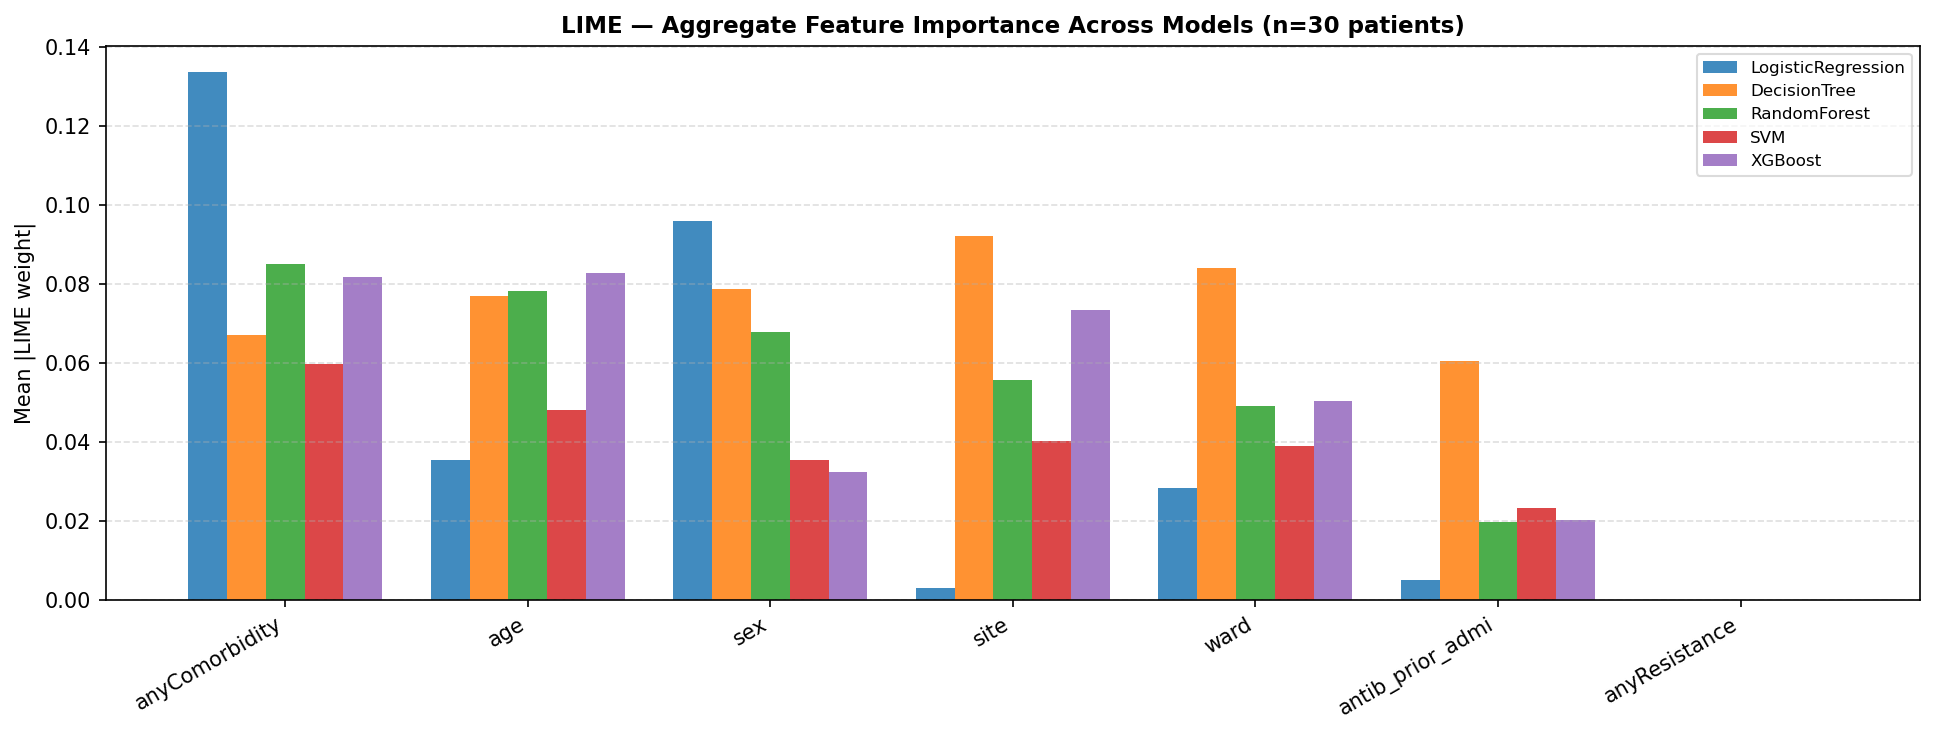

Saved LIME_pseudoglobal_all_models.png


In [90]:
N_LIME_GLOBAL = 30
rng           = np.random.default_rng(42)
sample_idxs   = rng.choice(len(X_test_lime), size=N_LIME_GLOBAL, replace=False)

lime_global_rows = []

for mname in MODEL_NAMES:
    print(f"LIME pseudo-global: {mname} ...", end=" ", flush=True)
    pred_fn = lime_predict_fn(models[mname])
    abs_weights = {d: [] for d in all_disp_names}

    for idx in sample_idxs:
        exp = lime_explainer.explain_instance(
            X_test_lime[idx], pred_fn,
            num_features=len(all_feat_names), num_samples=500, labels=(1,),
        )
        for feat, weight in exp.as_list(label=1):
            # LIME appends conditions; strip to base display name
            base = next((d for d in all_disp_names if feat.startswith(d)), feat)
            if base in abs_weights:
                abs_weights[base].append(abs(weight))

    row = {"model": mname}
    row.update({d: np.mean(v) if v else 0.0 for d, v in abs_weights.items()})
    lime_global_rows.append(row)
    print("done")

lime_global_df = pd.DataFrame(lime_global_rows).set_index("model")
lime_global_df.to_csv("LIME_pseudoglobal_all_models.csv")
print("\nSaved LIME_pseudoglobal_all_models.csv")
print(lime_global_df.round(4))

feat_order_lime = lime_global_df.mean(axis=0).sort_values(ascending=False).index.tolist()
bar_w = 0.8 / len(MODEL_NAMES)
x     = np.arange(len(feat_order_lime))

fig, ax = plt.subplots(figsize=(13, 5))
for k, mname in enumerate(MODEL_NAMES):
    offset = (k - len(MODEL_NAMES) / 2 + 0.5) * bar_w
    ax.bar(x + offset, lime_global_df.loc[mname, feat_order_lime],
           width=bar_w, label=mname, color=palette[k % len(palette)], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(feat_order_lime, rotation=30, ha="right")
ax.set_ylabel("Mean |LIME weight|")
ax.set_title(
    f"LIME — Aggregate Feature Importance Across Models (n={N_LIME_GLOBAL} patients)",
    fontweight="bold")
ax.legend(loc="upper right", fontsize=8, framealpha=0.7)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
fig.savefig("LIME_pseudoglobal_all_models.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved LIME_pseudoglobal_all_models.png")

## SHAP–LIME Agreement: Spearman Rank Correlation

Spearman rank correlation between the SHAP and LIME global feature importance
rankings for each model. ρ ≥ 0.7 (green) = strong agreement;
0.4–0.7 (orange) = moderate; < 0.4 (red) = weak.

SHAP–LIME Spearman Rank Agreement

             model  spearman_rho  p_value
LogisticRegression        0.9643   0.0005
      DecisionTree        0.7500   0.0522
      RandomForest        0.5000   0.2532
               SVM        0.6071   0.1482
           XGBoost        0.8571   0.0137


FixedFormatter should only be used together with FixedLocator


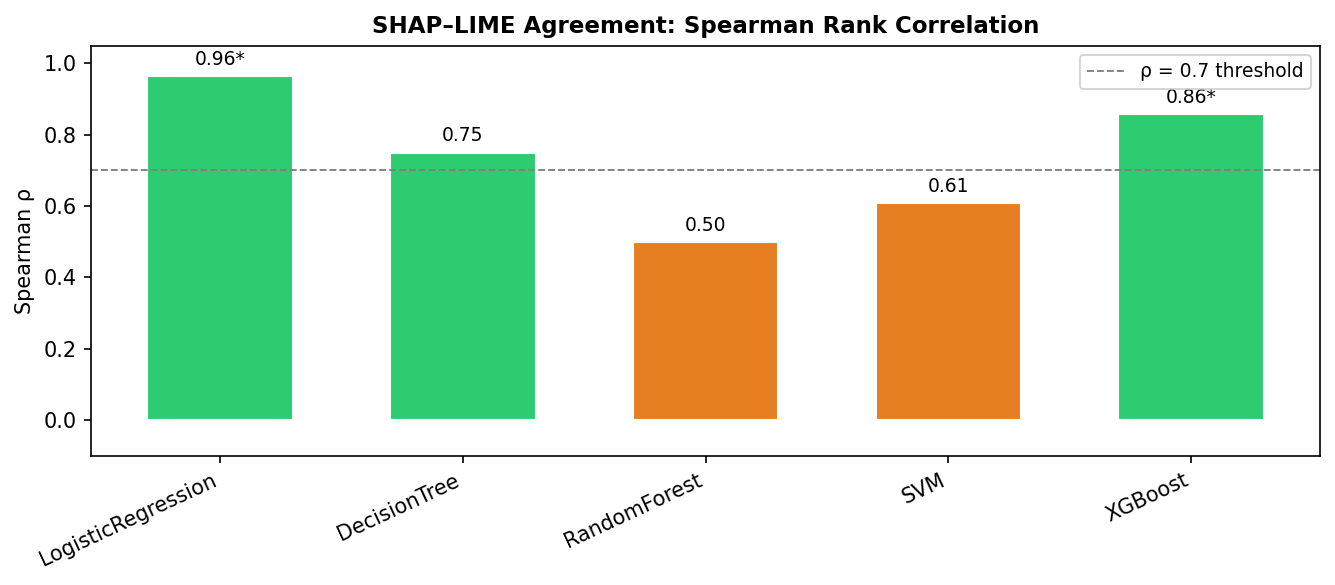


Saved SHAP_LIME_agreement.csv and SHAP_LIME_agreement.png
(* = p < 0.05)


In [91]:
# shared features in display-name space
shared_disp = [d for d in all_disp_names if d in shap_importance_df.columns]

agreement_rows = []
for mname in MODEL_NAMES:
    if mname not in shap_importance_df.index or mname not in lime_global_df.index:
        continue
    shap_rank = shap_importance_df.loc[mname, shared_disp].values
    lime_rank = lime_global_df.loc[mname, shared_disp].values
    rho, p    = spearmanr(shap_rank, lime_rank)
    agreement_rows.append({"model": mname, "spearman_rho": rho, "p_value": p})

agreement_df = pd.DataFrame(agreement_rows)
agreement_df.to_csv("SHAP_LIME_agreement.csv", index=False)

print("SHAP–LIME Spearman Rank Agreement\n")
print(agreement_df.to_string(index=False, float_format="{:.4f}".format))

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#2ecc71" if r >= 0.7 else "#e67e22" if r >= 0.4 else "#e74c3c"
          for r in agreement_df["spearman_rho"]]
bars = ax.bar(agreement_df["model"], agreement_df["spearman_rho"],
              color=colors, edgecolor="white", width=0.6)
ax.axhline(0.7, color="grey", linestyle="--", linewidth=0.9, label="\u03c1 = 0.7 threshold")
ax.set_ylim(-0.1, 1.05)
ax.set_ylabel("Spearman \u03c1")
ax.set_title("SHAP–LIME Agreement: Spearman Rank Correlation", fontweight="bold")
ax.set_xticklabels(agreement_df["model"], rotation=25, ha="right")
ax.legend(fontsize=9)

for bar, row in zip(bars, agreement_df.itertuples()):
    sig = "*" if row.p_value < 0.05 else ""
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.02,
            f"{row.spearman_rho:.2f}{sig}",
            ha="center", va="bottom", fontsize=9)

plt.tight_layout()
fig.savefig("SHAP_LIME_agreement.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved SHAP_LIME_agreement.csv and SHAP_LIME_agreement.png")
print("(* = p < 0.05)")